# E15-H78 - raw nearest-source count

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-09<br>
**Pipeline stage**: experiment - registered hypothesis `E15-H78` of the E13 campaign, stage A (measure)<br>
**Execution model**: opus

**Purpose** - measure whether a count of statements can be the source residual of the source-conditioned path.
`E13-H73` showed that the cost from a statement to its nearest source statement separates the statements of a
source's own summaries from statements of another article on the raw embeddings (AUC 0.9670), and that the mean
of those costs moves when supported statements are deleted (34.1% of one insertion). This notebook reads the same
cost as a per-statement flag and counts the flags.

**The lever** - the nearest-source cost of statement $i$ of a document $X$ against a source $S$, on the raw
embeddings (the anisotropy pre-pass is not applied), a flag above one cutoff $\tau$, and the count of the flags:

$$c_i = \min_{j} \sqrt{2 - 2\cos(x_i, s_j)}, \qquad f_i = \mathbb{1}[c_i > \tau], \qquad N(X) = \sum_{i=1}^{n} f_i$$

The flag is scored as a classifier of foreign statements against own statements by balanced accuracy:

$$\mathrm{BA} = \tfrac{1}{2}\big(\mathrm{TPR} + \mathrm{TNR}\big), \qquad \mathrm{TPR} = \frac{|\{f \in F : c_f > \tau\}|}{|F|}, \qquad \mathrm{TNR} = \frac{|\{o \in O : c_o \le \tau\}|}{|O|}$$

Nothing under `src/`, `docs/` or `tests/` is edited: the lever is prototyped here from the shipped `cost_matrix`.
The baseline is the shipped balanced residual `compute_source_conditioned(...).residual_a`.

**Terms used below**

- **own statement** - a statement of a document that belongs to the source the cost is read against: a summary of it, or a section of it
- **foreign statement** - a statement of the other article
- **short source statement** - a source statement of fewer than 5 words (markup tokens such as `-` and `##`, heading lines)
- **flag** - nearest-source cost above the cutoff; **count** - number of flagged statements of one document

**Four arms** - every number below is labelled with one of them

- **raw, short kept** - raw embeddings, short source statements kept: the source as the shipped default reader returns it. The registered arm; the verdict is read on it
- **raw, short removed** - raw embeddings, short source statements removed from the source (reported)
- **pre-pass, short kept** - the same flag after the shipped anisotropy pre-pass, cutoffs calibrated by the same rule (reported)
- **pre-pass, short removed** - both changes together (reported)

**Approach**

1. **Kill-gate first** - AUC of the nearest-source cost, own gold-tier statements against the foreign set, on each calibration half, raw embeddings; below 0.90 on either half the hypothesis is killed
2. **Harness check** - reproduce the numbers the record's Evidence line cites from `E13-H73` and `E14-H76`
3. **Registered experiment** - cutoff on the calibration half, held-out balanced accuracy in both directions; verbatim extract `source[0::7][:10]`; second source article with the mean cutoff and no refit
4. **Reported without a bar** - count under 1 to 4 insertions and deletions, mean cost per tier, adversarial summaries against per-statement entailment, the shipped residual on the same insertions
5. **Guardrails, measured** - `V` on the naive panel, default-path bit identity against the saved 1.1.5 baseline, source-tree byte digests
6. **Verdict** - the acceptance bar of the record, applied literally

**Outputs**

- Kill-gate table and cost distributions
- Calibration curves, bar readings of the four arms, dose figures
- Metrics JSON `reports/E15-H78-raw-nearest-source-count-metrics.json`

## Environment

No GPU is used. The path under test is the shipped OpenVINO INT8 encoder on CPU, so `CUDA_VISIBLE_DEVICES` is
set empty before any model import and the models resolve offline through `docdistance.json`.

In [1]:
import os
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # no GPU: the shipped OpenVINO INT8 CPU path is the path under test
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["HF_HUB_OFFLINE"] = "1"                 # models resolve from the local cache through docdistance.json
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

warnings.filterwarnings("ignore")
print("environment set: CPU only, models offline")

environment set: CPU only, models offline


## Imports

The shipped `docdistance` core is imported and never edited. POT runs inside the shipped functions; `scipy`
supplies the rank correlations and `threadpoolctl` limits BLAS to one thread for the small SVD of the pre-pass.

In [2]:
%load_ext autoreload
%autoreload 2

# Standard library
import contextlib                      # silence the model-load stderr output
import gzip                            # read the saved default-path baseline
import hashlib                         # per-file byte digests of src/, tests/, docs/ for the no-edit guardrail
import io                              # sink for the redirected stderr
import json                            # metrics JSON and fixture fingerprints
import re                              # remove the HTML provenance comment of the wergeland file
import subprocess                      # git status and uptime
import sys                             # interpreter path and the progress-bar stream
from pathlib import Path               # fixture and report paths

# Scientific
import numpy as np                     # arrays and seeded dose draws
import ot                              # POT version line; the solves run inside the shipped functions
from scipy.stats import spearmanr      # dose-response and entailment rank correlations
from threadpoolctl import threadpool_limits   # one BLAS thread for the pre-pass SVD

# Visualisation
import matplotlib.pyplot as plt        # inline figures, object-oriented API

# Console and progress
from rich.console import Console, Group   # one render call per output block
from rich.markup import escape         # statement texts are printed literally
from rich.panel import Panel
from rich.table import Table
from tqdm import tqdm                  # progress on the pre-pass and dose loops

# The shipped package under test - imported, never edited
import docdistance
from docdistance.distance import (
    all_but_the_top,                   # the anisotropy pre-pass
    closeness,                         # distance to 0-1 closeness
    compute_source_conditioned,        # shipped source-conditioned assembly, the balanced baseline
    cost_matrix,                       # ground cost sqrt(2 - 2cos)
    opw_gap,                           # default-path structural reading for the guardrail
    smd,                               # default-path symmetric distance for the guardrail
)
from docdistance.pipeline import DocDistance   # shipped reader, segmenter and OpenVINO INT8 encoder

console = Console(width=180)
uptime = subprocess.run(["uptime"], capture_output=True, text=True).stdout.strip()
print(f"python {sys.version.split()[0]} at {sys.executable}\n"
      f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__}\n"
      f"uptime: {uptime}")

python 3.14.8 at /home/lab/workspace/learning/projects/docdistance/.venv/bin/python
docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6
uptime: 13:08:31 up 1 day, 14:29,  0 user,  load average: 19.67, 63.62, 78.26


## Reproducibility

Segmentation, the INT8 encode, the pre-pass SVD and the exact transport solve take no random input. The seed
governs the dose construction only: which foreign statements are inserted and which statements are deleted.

In [3]:
SEED = 42
np.random.seed(SEED)
print(f"SEED = {SEED}")

SEED = 42


## Configuration

Every bar, cutoff rule and reading rule is stated in this section, and the configuration cell executes before any
measurement cell. The kill-gate threshold, the three acceptance thresholds, the cutoff rule and the document split
are the record's and the task notes' and are used unchanged. Where the record `E15-H78` leaves a choice, the rule
below is the executor's and is marked **executor's rule**; its second reading is reported beside the bar reading.

This notebook was executed more than once. After the first execution these were added or changed: the reading
cells; six descriptive output lines (nearest source statement per scored statement, size of one statement, the
short extract statement, the flagged own statements of the second article, median own cost and lowest ibm cost,
documents with a negative Spearman); the wording of the prediction table, of the verdict number and of the result
summary; table and figure layout. No bar, cutoff rule, split or reading rule of this section changed after the
first execution, and every measured number of the first execution's metrics JSON is unchanged in the last one.

- **Split (task notes)** - gold tier = the 7 ibm summaries that are not `adv1-a`, `adv1-b`, `adv2-a`, `adv2-b`. The anchor `exec-summary-gold-opus-4-6.md` is in half A; the other six, in sorted file-name order, alternate B, A, B, A, B, A. The cell derives the split from the file names and prints it
- **Registered arm** - raw embeddings, short source statements kept: the source as `DocDistance.embed_statements(path)` returns it with default arguments. The three reported arms are listed in the header
- **Cutoff rule (record)** - grid 0.000 to 2.000 in steps of 0.005 (the range of the ground cost); the cutoff maximises calibration balanced accuracy and is the midpoint of the longest run of consecutive grid points at the maximum. **Executor's rule** - the midpoint is (first + last) / 2 of the run, so it lies halfway between two grid points when the run has an even number of points; of two runs of equal length the lower one is taken. Held-out balanced accuracy is also reported at every grid point of the run, as a minimum and a maximum
- **Foreign set (record)** - wergeland statements of 5 words or more, HTML provenance comment of the fixture file removed, 38 statements (the `E13-H73` set)
- **Foreign set in clause (1), executor's rule** - the record splits the documents and names one foreign set. The bar reading uses the whole foreign set in calibration and in scoring, as the kill-gate line of the record states it ("against the foreign set, on each calibration half"). In that reading the scored foreign statements also took part in the choice of the cutoff. The second reading divides the foreign set by position in the article, even positions with half A and odd positions with half B, so the calibration set and the scored set share no statement
- **Clause (2)** - the count of the 10-statement extract `source[0::7][:10]` is read under each of the two calibrated cutoffs; the clause is met when both read 0
- **Clause (3)** - cutoff = mean of the two cutoffs of the arm, no refit. Source = the wergeland article through the shipped default reader: the HTML provenance comment is part of the file and stays, short statements stay. Own = the statements of `werg-a`, `werg-b`, `werg-c` in the structure fixture; foreign = the statements of the 7 gold-tier ibm summaries. **Executor's rule, second readings** - the comment removed from the source; the back-translations `werg-a~bt`, `werg-b~bt`, `werg-c~bt` as own statements, which are not copies of source statements
- **Pre-pass arms** - call shape `all_but_the_top({"a": X, "b": X, "s": S}, k=1)`, the pool of `compute_source_conditioned(X, X, S)`. The pre-pass depends on the pooled statements, so in clause (1) each foreign statement is appended alone to each host summary and read inside that call; in clauses (2) and (3) each document is one call
- **Insertion doses** - per (document, seed) four foreign statements drawn without replacement; dose `k` appends the first `k`. 14 seeds, seed 42, the draw order of `E13-H73`, so the doses are the ones `E13-H73` scored. In the disjoint reading the draws come from the foreign half that took no part in the calibration (second generator, seed 43)
- **Deletion doses** - per (document, seed) one random order of the statements (the `E13-H73` orders). *Any statement*: dose `k` removes the first `k` of the order. *Supported statements*: dose `k` removes the first `k` statements of the order that are not flagged
- **Entailment label, executor's rule** - the record asks for an AUC of the cost against 1 - entailment and names no threshold. A statement is labelled not entailed when 1 - entailment is above 0.5. The concordance over all pairs of statements with different entailment and the Spearman correlation are reported beside it; neither needs a threshold
- **Harness check, executor's rule** - the record names no sanity check. The notebook reproduces the seven numbers the record's Evidence line cites, each at the decimals the record prints. A number that does not reproduce returns `Blocked`
- **Verdict** - `Killed-at-gate` when the gate fires; `Blocked` when the harness check or a guardrail fails; `Promoted` when the three clauses hold on the registered arm; otherwise `Refuted`, or `Refuted (null)` when the held-out balanced accuracy is at or below 0.5 in both directions (a flag that carries no information reads 0.5)
- **Direction of the prediction** - read per predicted effect with no threshold added. Held-out and second-article balanced accuracy: the flag marks foreign statements more often than own statements (TPR above FPR) in every scored set. Shipped residual: median per-document Spearman of the dose against `residual_a` below zero, read with the pre-pass off, the setting of the cited `E13-H73` number -0.2571; the default call is reported beside it. Cutoff: an interval for a parameter has no direction, so it is reported as not defined by the record. `direction_matched` is true only when the three effects that have a direction read matched and the cutoff lies in its registered interval

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
IBM_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption"
SUMMARY_DIR = IBM_DIR / "summaries"                                               # the 11 ibm summaries
SOURCE_FILE = IBM_DIR / "source/source-article.md"                                # ibm source, 70 statements
WERG_FILE = ROOT / "data/interim/ai-society-wergeland/source/source-article.md"   # foreign statements and second source
STRUCTURE_FILE = ROOT / "data/processed/structure-fixture/statements.json"        # werg-a, werg-b, werg-c and back-translations
GROUNDING_NPZ = ROOT / "data/interim/E12-H69-grounding-signals.npz"               # per-statement entailment
GROUNDING_TXT = ROOT / "data/interim/E12-H69-grounding-texts.json"                # statement fingerprint of those signals
BASELINE_FILE = ROOT / "reports/E13-campaign/baseline/default-path.json.gz"       # saved 1.1.5 default path
REPORT = ROOT / "reports/E15-H78-raw-nearest-source-count-metrics.json"           # metrics JSON, the only file written

DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
ANCHOR = "gold"
LABELS = [label for _, label, _ in DOCS]
FILE_OF = {label: fname for fname, label, _ in DOCS}
TIER = {label: tier for _, label, tier in DOCS}
TIERS = ("gold", "adv1", "adv2")
GOLD_TIER = [l for l in LABELS if TIER[l] == "gold"]             # 7 documents, the anchor included
GOLD_NONREF = [l for l in GOLD_TIER if l != ANCHOR]              # 6 documents of the naive panel
ADV = [l for l in LABELS if TIER[l] != "gold"]                   # 4 adversarial documents; V is out of 6 x 4 = 24

# calibration split by document (task notes): anchor in half A, the other six in sorted file-name order B, A, B, A, B, A
SPLIT_PATTERN = ("B", "A", "B", "A", "B", "A")
HALF_OF = {ANCHOR: "A"}
HALF_OF.update(dict(zip(sorted(GOLD_NONREF, key=FILE_OF.get), SPLIT_PATTERN)))
HALF = {half: [l for l in GOLD_TIER if HALF_OF[l] == half] for half in ("A", "B")}
DIRECTIONS = {"A→B": ("A", "B"), "B→A": ("B", "A")}             # name → (calibration half, held-out half)
HELD_DIRECTION = {l: next(d for d, (_, held) in DIRECTIONS.items() if held == HALF_OF[l]) for l in GOLD_TIER}

# the four arms - every reported number carries one of these keys
ARMS = {
    "raw_kept":    {"embedding": "raw", "short": "kept",    "label": "raw, short kept (registered)"},
    "raw_removed": {"embedding": "raw", "short": "removed", "label": "raw, short removed"},
    "pre_kept":    {"embedding": "pre", "short": "kept",    "label": "pre-pass, short kept"},
    "pre_removed": {"embedding": "pre", "short": "removed", "label": "pre-pass, short removed"},
}
RAW_ARMS = [a for a in ARMS if ARMS[a]["embedding"] == "raw"]
PRE_ARMS = [a for a in ARMS if ARMS[a]["embedding"] == "pre"]
VERDICT_ARM = "raw_kept"
FOREIGN_READINGS = {"whole": "foreign set whole (registered)", "disjoint": "foreign set in disjoint halves"}
VERDICT_FOREIGN = "whole"

# statements
MIN_WORDS = 5                    # foreign set: 5 words or more; a source statement under 5 words is a short source statement
N_FOREIGN_EXPECTED = 38          # the E13-H73 foreign set
WERG_KEYS = ["werg-a", "werg-b", "werg-c"]                       # second-article own statements (structure fixture)
OWN_SETS = {"sections": WERG_KEYS, "back-translations": [f"{key}~bt" for key in WERG_KEYS]}
COMMENTS = ("comment kept", "comment removed")                   # HTML provenance comment of the wergeland file
REGISTERED_SECOND = ("comment kept", "sections")                 # shipped default reader, registered own statements

# cutoff rule (record E15-H78)
GRID_STEP, GRID_MAX = 0.005, 2.0
GRID = np.round(np.arange(int(round(GRID_MAX / GRID_STEP)) + 1) * GRID_STEP, 3)

# kill-gate and acceptance bar (record E15-H78)
GATE_AUC_MIN = 0.90              # AUC on each calibration half, raw embeddings
BAR_HELD_BA = 0.90               # clause (1): held-out balanced accuracy, both directions
BAR_EXTRACT_FLAGGED = 0          # clause (2): flagged statements of the verbatim extract
BAR_SECOND_BA = 0.85             # clause (3): second-article balanced accuracy, mean cutoff, no refit
EXTRACT_STRIDE, EXTRACT_N = 7, 10                                # X = source[0::7][:10], the DEF-TRANS-8 extract
NO_INFORMATION_BA = 0.5          # balanced accuracy of a flag that carries no information

# prediction (record E15-H78)
PRED_CUTOFF = (0.33, 0.45)
PRED_HELD_BA = (0.90, 0.96)
PRED_SECOND_BA = (0.85, 0.95)

# doses
KS = (1, 2, 3, 4)                # statements inserted or deleted
INSERT_KS = (0,) + KS
N_SEEDS = 14                     # draws per document, as in E13-H73

# reported readings
ENTAIL_LABEL_MIN = 0.5           # executor's rule: not entailed when 1 - entailment is above this

# harness check: the numbers the record's Evidence line cites → (value, decimals)
EVIDENCE = {
    "AUC, 98 own x 38 foreign statements, raw embeddings (E13-H73)": (0.9670, 4),
    "AUC, same pairs, after the pre-pass (E13-H73)": (0.7889, 4),
    "verbatim extract, closeness of the mean nearest-source cost, raw (E13-H73)": (0.9999, 4),
    "verbatim extract, shipped closeness_a (E13-H73)": (0.3224, 4),
    "shipped residual, pre-pass off, median per-document Spearman under insertions, 11 documents (E13-H73)": (-0.2571, 4),
    "mean nearest-source cost, median |change| under deletions over one insertion, raw (E13-H73)": (0.341, 3),
    "one-word statements among the 70 ibm source statements (E14-H76)": (22, 0),
}

# guardrail references
PANEL_ROW = {"V": 0, "margin_pts": 4.71, "dprime": 4.68, "R": 1.670, "DR": 0.0873}   # naive row, OpenVINO INT8
SC_FIELDS = ("d_sel", "residual_a", "residual_b", "closeness_a", "closeness_b")      # saved source-conditioned keys

# one palette for console and figures: green = own, red = foreign, blue = the flag on raw embeddings,
# purple = the same flag after the pre-pass, grey = the shipped baseline, orange = information-loss tier
C_OWN, C_OWN_B, C_FOREIGN, C_WARN = "#2ECC71", "#1E8449", "#E74C3C", "#F39C12"
C_LEVER, C_PRE, C_BASELINE = "#3498DB", "#9B59B6", "#7F8C8D"
TIER_COLOR = {"gold": C_OWN, "adv1": C_WARN, "adv2": C_FOREIGN}
ARM_COLOR = {"raw_kept": C_LEVER, "raw_removed": C_LEVER, "pre_kept": C_PRE, "pre_removed": C_PRE}
ARM_HATCH = {"raw_kept": "", "raw_removed": "//", "pre_kept": "", "pre_removed": "//"}   # hatch = short source statements removed
ARM_TICK = {"raw_kept": "raw\nshort kept", "raw_removed": "raw\nshort removed",
            "pre_kept": "pre-pass\nshort kept", "pre_removed": "pre-pass\nshort removed"}

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold cyan"); cfg.add_column()
cfg.add_row("Fixture", f"{len(GOLD_TIER)} gold-tier ibm summaries, ibm source, foreign statements and second source from the wergeland article")
cfg.add_row("Split by document", "\n".join(f"half {half}: {', '.join(f'{l} ({FILE_OF[l]})' for l in HALF[half])}" for half in HALF))
cfg.add_row("Directions", ", ".join(f"{name}: cutoff on half {cal}, scored on half {held}" for name, (cal, held) in DIRECTIONS.items()))
cfg.add_row("Arms", "\n".join(f"{key}: {arm['label']}" for key, arm in ARMS.items()))
cfg.add_row("Cutoff rule", f"grid 0 to {GRID_MAX} step {GRID_STEP} ({len(GRID)} points), maximum calibration balanced accuracy, "
                           "midpoint of the longest run at the maximum")
cfg.add_row("Kill-gate", f"AUC of nearest-source cost, own gold-tier statements against the foreign set, below {GATE_AUC_MIN} on either "
                         f"calibration half kills; arm {VERDICT_ARM}")
cfg.add_row("Acceptance bar", f"(1) held-out balanced accuracy >= {BAR_HELD_BA} in both directions AND (2) extract source"
                              f"[0::{EXTRACT_STRIDE}][:{EXTRACT_N}] reads {BAR_EXTRACT_FLAGGED} flagged AND (3) second-article balanced accuracy "
                              f">= {BAR_SECOND_BA} at the mean cutoff")
cfg.add_row("Verdict reading", f"arm {VERDICT_ARM}, {FOREIGN_READINGS[VERDICT_FOREIGN]}, second source {REGISTERED_SECOND[0]}, own {REGISTERED_SECOND[1]}")
cfg.add_row("Prediction", f"cutoff in {PRED_CUTOFF}, held-out balanced accuracy in {PRED_HELD_BA}, second article in {PRED_SECOND_BA}, "
                          "shipped residual falls under the same insertions")
cfg.add_row("Doses", f"k in {KS} insertions and deletions, {N_SEEDS} seeds per document, SEED {SEED}")
cfg.add_row("Entailment label", f"not entailed when 1 - entailment > {ENTAIL_LABEL_MIN} (executor's rule)")
cfg.add_row("Harness check", f"{len(EVIDENCE)} numbers of the record's Evidence line, each at the record's decimals")
cfg.add_row("Metrics out", str(REPORT.relative_to(ROOT)))
console.print(Panel(cfg, title="E15-H78 configuration", border_style="cyan"))

╭───────────────────────────────────────────────────────────────────────────── E15-H78 configuration ──────────────────────────────────────────────────────────────────────────────╮
│ Fixture            7 gold-tier ibm summaries, ibm source, foreign statements and second source from the wergeland article                                                        │
│ Split by document  half A: gold (exec-summary-gold-opus-4-6.md), v2 (exec-summary-2-opus-4-6.md), sonnet (exec-summary-sonnet-4-6.md), haiku (exec-summary-haiku-4-5.md)         │
│                    half B: gold-2 (exec-summary-gold-2-opus-4-6.md), v1 (exec-summary-1-opus-4-6.md), opus (exec-summary-opus-4-6.md)                                            │
│ Directions         A→B: cutoff on half A, scored on half B, B→A: cutoff on half B, scored on half A                                                                              │
│ Arms               raw_kept: raw, short kept (registered)                                                                                                                        │
│                    raw_removed: raw, short removed                                                                                                                               │
│                    pre_kept: pre-pass, short kept                                                                                                                                │
│                    pre_removed: pre-pass, short removed                                                                                                                          │
│ Cutoff rule        grid 0 to 2.0 step 0.005 (401 points), maximum calibration balanced accuracy, midpoint of the longest run at the maximum                                      │
│ Kill-gate          AUC of nearest-source cost, own gold-tier statements against the foreign set, below 0.9 on either calibration half kills; arm raw_kept                        │
│ Acceptance bar     (1) held-out balanced accuracy >= 0.9 in both directions AND (2) extract source[0::7][:10] reads 0 flagged AND (3) second-article balanced accuracy >= 0.85   │
│                    at the mean cutoff                                                                                                                                            │
│ Verdict reading    arm raw_kept, foreign set whole (registered), second source comment kept, own sections                                                                        │
│ Prediction         cutoff in (0.33, 0.45), held-out balanced accuracy in (0.9, 0.96), second article in (0.85, 0.95), shipped residual falls under the same insertions           │
│ Doses              k in (1, 2, 3, 4) insertions and deletions, 14 seeds per document, SEED 42                                                                                    │
│ Entailment label   not entailed when 1 - entailment > 0.5 (executor's rule)                                                                                                      │
│ Harness check      7 numbers of the record's Evidence line, each at the record's decimals                                                                                        │
│ Metrics out        reports/E15-H78-raw-nearest-source-count-metrics.json                                                                                                         │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Data loading and embedding

The ibm source, the 11 summaries and the wergeland article are read with the shipped default reader
`DocDistance.embed_statements(path)`: title lines removed, shipped segmenter, shipped OpenVINO INT8 encoder. The
foreign set is built with the `E13-H73` code. The ibm segmentation is compared with the statement fingerprint
that `E12-H69` stored beside its entailment signals, so those signals can be reused statement by statement.

In [5]:
HTML_COMMENT_RE = re.compile(r"<!--.*?-->", re.DOTALL)


def body_of(text: str) -> str:
    """Document body with markdown title lines removed - the loader of E13-H73"""
    return "\n".join(ln for ln in text.splitlines() if not ln.startswith("# ")).strip()


def long_enough(texts: list) -> np.ndarray:
    """True for a statement of MIN_WORDS words or more"""
    return np.array([len(t.split()) >= MIN_WORDS for t in texts])


with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance(backend="openvino", offline=True)
    S_TEXTS, E_S = dd.embed_statements(SOURCE_FILE)                      # ibm source, shipped default reader
    TEXTS, E = {}, {}
    for fname, label, _ in DOCS:
        TEXTS[label], E[label] = dd.embed_statements(SUMMARY_DIR / fname)
    W2_TEXTS, E_W2 = dd.embed_statements(WERG_FILE)                      # second source, shipped default reader (comment kept)
    # the E13-H73 foreign fixture: the HTML provenance comment of the file is removed before segmentation
    W_TEXTS = dd.segmenter.split(body_of(HTML_COMMENT_RE.sub("", WERG_FILE.read_text(encoding="utf-8"))))
    E_W = dd.encoder.encode(W_TEXTS)
    structure = json.loads(STRUCTURE_FILE.read_text(encoding="utf-8"))
    WERG_TEXTS = {key: structure[key]["statements"] for keys in OWN_SETS.values() for key in keys}
    E_WERG = {key: dd.encoder.encode(texts) for key, texts in WERG_TEXTS.items()}

KEEP_S, KEEP_W2, PROSE = long_enough(S_TEXTS), long_enough(W2_TEXTS), long_enough(W_TEXTS)
E_F = E_W[PROSE]                                                         # the foreign set
F_TEXTS = [t for t, keep in zip(W_TEXTS, PROSE) if keep]
SOURCE = {"kept": E_S, "removed": E_S[KEEP_S]}                           # ibm source, short statements kept / removed
SECOND_SOURCE = {("comment kept", "kept"): E_W2, ("comment kept", "removed"): E_W2[KEEP_W2],
                 ("comment removed", "kept"): E_W, ("comment removed", "removed"): E_W[PROSE]}

ALL_FOREIGN = np.arange(len(E_F))
FOREIGN_OF = {"whole": {"A": ALL_FOREIGN, "B": ALL_FOREIGN},             # the foreign statements scored with each document half
              "disjoint": {"A": ALL_FOREIGN[0::2], "B": ALL_FOREIGN[1::2]}}

fingerprint = json.loads(GROUNDING_TXT.read_text(encoding="utf-8"))
fingerprint_match = fingerprint == {"S": S_TEXTS, "docs": TEXTS}
n_one_word_source = int(sum(len(t.split()) == 1 for t in S_TEXTS))


def squeeze(text: str) -> str:
    """Whitespace-normalised text for the verbatim comparison"""
    return " ".join(text.split())


werg_sections = [t for key in WERG_KEYS for t in WERG_TEXTS[key]]
second_source_texts = {squeeze(t) for t in W2_TEXTS}
sections_in_second_source = int(sum(squeeze(t) in second_source_texts for t in werg_sections))
sections_equal_foreign_set = sorted(map(squeeze, werg_sections)) == sorted(map(squeeze, F_TEXTS))
bt_in_second_source = int(sum(squeeze(t) in second_source_texts for key in OWN_SETS["back-translations"] for t in WERG_TEXTS[key]))

fx = Table(title="Fixture", header_style="bold cyan")
fx.add_column("set"); fx.add_column("role"); fx.add_column("statements", justify="right")
for label in LABELS:
    role = f"{TIER[label]} tier" + (f", half {HALF_OF[label]}" if label in HALF_OF else ", not in the split")
    fx.add_row(label, role, str(len(E[label])), style=TIER_COLOR[TIER[label]])
for half in HALF:
    fx.add_row(f"half {half}", f"{len(HALF[half])} documents", str(sum(len(E[l]) for l in HALF[half])), style="bold")
fx.add_row("ibm source, short kept", "source, registered", str(len(SOURCE["kept"])))
fx.add_row("ibm source, short removed", "source, reported", str(len(SOURCE["removed"])))
fx.add_row("wergeland, comment removed, 5 words or more", "foreign set", str(len(E_F)))
for (comment, short), emb in SECOND_SOURCE.items():
    fx.add_row(f"wergeland, {comment}, short {short}", "second source" + (", registered" if (comment, short) == ("comment kept", "kept") else ""),
               str(len(emb)))
for name, keys in OWN_SETS.items():
    fx.add_row(f"wergeland {name}: {', '.join(keys)}", "second-article own statements",
               " + ".join(str(len(E_WERG[key])) for key in keys) + f" = {sum(len(E_WERG[key]) for key in keys)}")
console.print(Group(
    fx,
    f"embedding shape {E_S.shape}, dtype {E_S.dtype} | ibm segmentation equals the E12-H69 fingerprint (source and 11 summaries): {fingerprint_match}",
    f"ibm source statements under {MIN_WORDS} words: {int((~KEEP_S).sum())} of {len(S_TEXTS)}; with exactly one word: {n_one_word_source}; "
    f"distinct texts among the short ones: {sorted(set(t for t, keep in zip(S_TEXTS, KEEP_S) if not keep))}",
    f"wergeland source through the shipped reader, statements under {MIN_WORDS} words: {int((~KEEP_W2).sum())} of {len(W2_TEXTS)}",
    f"werg-a, werg-b, werg-c statements whose text is a statement of the second source (comment kept): {sections_in_second_source} of "
    f"{len(werg_sections)}; the same texts as the foreign set: {sections_equal_foreign_set}; back-translated statements whose text is a "
    f"statement of the second source: {bt_in_second_source} of {sum(len(WERG_TEXTS[key]) for key in OWN_SETS['back-translations'])}",
))
assert fingerprint_match, "the ibm segmentation differs from the E12-H69 fingerprint"
assert len(E_S) == 70, "the ibm source must segment into 70 statements"
assert len(E_F) == N_FOREIGN_EXPECTED, "the foreign set must be the 38 statements of E13-H73"
assert sorted(HALF["A"]) == sorted(["gold", "v2", "haiku", "sonnet"]) and sorted(HALF["B"]) == sorted(["v1", "gold-2", "opus"])

                                                      Fixture                                                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ set                                                          ┃ role                          ┃        statements ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ gold                                                         │ gold tier, half A             │                10 │
│ gold-2                                                       │ gold tier, half B             │                12 │
│ v1                                                           │ gold tier, half B             │                11 │
│ v2                                                           │ gold tier, half A             │                11 │
│ opus                                                         │ gold tier, half B             │                11 │
│ sonnet                                                       │ gold tier, half A             │                 9 │
│ haiku                                                        │ gold tier, half A             │                13 │
│ adv1-a                                                       │ adv1 tier, not in the split   │                 8 │
│ adv1-b                                                       │ adv1 tier, not in the split   │                 9 │
│ adv2-a                                                       │ adv2 tier, not in the split   │                 1 │
│ adv2-b                                                       │ adv2 tier, not in the split   │                 3 │
│ half A                                                       │ 4 documents                   │                43 │
│ half B                                                       │ 3 documents                   │                34 │
│ ibm source, short kept                                       │ source, registered            │                70 │
│ ibm source, short removed                                    │ source, reported              │                42 │
│ wergeland, comment removed, 5 words or more                  │ foreign set                   │                38 │
│ wergeland, comment kept, short kept                          │ second source, registered     │                52 │
│ wergeland, comment kept, short removed                       │ second source                 │                42 │
│ wergeland, comment removed, short kept                       │ second source                 │                44 │
│ wergeland, comment removed, short removed                    │ second source                 │                38 │
│ wergeland sections: werg-a, werg-b, werg-c                   │ second-article own statements │ 11 + 13 + 14 = 38 │
│ wergeland back-translations: werg-a~bt, werg-b~bt, werg-c~bt │ second-article own statements │ 11 + 13 + 14 = 38 │
└──────────────────────────────────────────────────────────────┴───────────────────────────────┴───────────────────┘
embedding shape (70, 768), dtype float32 | ibm segmentation equals the E12-H69 fingerprint (source and 11 summaries): True
ibm source statements under 5 words: 28 of 70; with exactly one word: 22; distinct texts among the short ones: ['##', '## Key findings', '## Methodology', '###', '-', 'About IBM', 
'Overview', 'Source: IBM.', 'Trustworthy and governed AI', 'Workforce impact']
wergeland source through the shipped reader, statements under 5 words: 10 of 52
werg-a, werg-b, werg-c statements whose text is a statement of the second source (comment kept): 36 of 38; the same texts as the foreign set: False; back-translated statements 
whose text is a statement of the second source: 1 of 38

### Default-path snapshot before any arm

The shipped default path is recorded before the lever is prototyped: the 10 anchor distances and order gaps of
the naive panel and the three saved source-conditioned results, in the pair orientation of the saved 1.1.5
baseline `reports/E13-campaign/baseline/default-path.json.gz`. Per-file byte digests of `src/`, `tests/` and `docs/`
are taken at the same time. The guardrail section repeats all of it after the arms have run.

In [6]:
STEM = {label: fname.removeprefix("exec-summary-").removesuffix(".md") for fname, label, _ in DOCS}
LABEL_OF = {stem: label for label, stem in STEM.items()}
with gzip.open(BASELINE_FILE, "rt", encoding="utf-8") as fh:
    BASELINE = json.load(fh)
ANCHOR_KEYS = sorted(key for key in BASELINE["pairs"] if STEM[ANCHOR] in key.split("|"))
GROUNDED_KEYS = sorted(BASELINE["grounded"])
ANCHOR_PAIRS = [tuple(LABEL_OF[stem] for stem in key.split("|")) for key in ANCHOR_KEYS]
GROUNDED_PAIRS = [tuple(LABEL_OF[stem] for stem in key.split("|")) for key in GROUNDED_KEYS]
SAVED = {
    "smd": np.array([BASELINE["pairs"][key]["semantic"]["smd"] for key in ANCHOR_KEYS]),
    "order_gap": np.array([BASELINE["pairs"][key]["structural"]["order_gap"] for key in ANCHOR_KEYS]),
    "source_conditioned": np.array([[BASELINE["grounded"][key][f] for f in SC_FIELDS] for key in GROUNDED_KEYS]),
}


def default_path_snapshot() -> dict:
    """Shipped default-path outputs in the pair orientation of the saved baseline"""
    conditioned = [compute_source_conditioned(E[a], E[b], E_S) for a, b in GROUNDED_PAIRS]
    return {
        "smd": np.array([smd(E[a], E[b]) for a, b in ANCHOR_PAIRS]),
        "order_gap": np.array([opw_gap(E[a], E[b]) for a, b in ANCHOR_PAIRS]),
        "source_conditioned": np.array([[getattr(r, f) for f in SC_FIELDS] for r in conditioned]),
    }


def panel_metrics(smd_values: np.ndarray) -> dict:
    """The naive panel of E12-H66: V out of 24, boundary margin, d', contrast ratio R, dynamic range DR"""
    dist = {(a if b == ANCHOR else b): float(d) for (a, b), d in zip(ANCHOR_PAIRS, smd_values)}
    g = np.array([dist[l] for l in GOLD_NONREF])
    a = np.array([dist[l] for l in ADV])
    pooled_std = float(np.sqrt((g.var() + a.var()) / 2))
    return {
        "V": int(sum(1 for gg in g for aa in a if gg >= aa)),
        "margin_pts": float((closeness(g.max()) - closeness(a.min())) * 100),
        "dprime": float((a.mean() - g.mean()) / pooled_std),
        "R": float(a.mean() / g.mean()),
        "DR": float(np.concatenate([g, a]).std()),
    }


def file_digests(folder: str) -> dict:
    """sha256 of every file under a repository folder, keyed by its path relative to the repository root"""
    skipped = {"__pycache__", ".ipynb_checkpoints", "@archive"}
    return {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
            for path in sorted((ROOT / folder).rglob("*")) if path.is_file() and not skipped.intersection(path.parts)}


SNAP_BEFORE = default_path_snapshot()
PANEL_BEFORE = panel_metrics(SNAP_BEFORE["smd"])
DIGEST_BEFORE = {folder: file_digests(folder) for folder in ("src", "tests", "docs")}
saved_equal_before = {key: bool(np.array_equal(SNAP_BEFORE[key], SAVED[key])) for key in SAVED}

# from here on BLAS runs on one thread, which shortens the many small SVDs of the pre-pass on this 64-thread
# machine; the guardrail section restores the default thread count and checks that the readings are identical
BLAS_LIMIT = threadpool_limits(limits=1, user_api="blas")

console.print(Group(
    f"naive panel, shipped smd against the anchor: V {PANEL_BEFORE['V']}/24, margin {PANEL_BEFORE['margin_pts']:+.2f} pts, "
    f"d' {PANEL_BEFORE['dprime']:.2f}, R {PANEL_BEFORE['R']:.3f}, DR {PANEL_BEFORE['DR']:.4f} "
    f"(primer row: V 0/24, margin +{PANEL_ROW['margin_pts']}, d' {PANEL_ROW['dprime']}, R {PANEL_ROW['R']:.3f}, DR {PANEL_ROW['DR']})",
    f"equal to the saved 1.1.5 baseline (np.array_equal): smd {saved_equal_before['smd']}, "
    f"order_gap {saved_equal_before['order_gap']}, source-conditioned {saved_equal_before['source_conditioned']}",
    f"per-file digests recorded: src/ {len(DIGEST_BEFORE['src'])} files, tests/ {len(DIGEST_BEFORE['tests'])} files, "
    f"docs/ {len(DIGEST_BEFORE['docs'])} files; BLAS limited to 1 thread for the arms",
))

naive panel, shipped smd against the anchor: V 0/24, margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873 (primer row: V 0/24, margin +4.71, d' 4.68, R 1.670, DR 0.0873)
equal to the saved 1.1.5 baseline (np.array_equal): smd True, order_gap True, source-conditioned True
per-file digests recorded: src/ 15 files, tests/ 9 files, docs/ 45 files; BLAS limited to 1 thread for the arms

## The flag as code

The nearest-source cost, the pre-pass call shape, the AUC, the balanced accuracy and the record's cutoff rule.
The count is a **score, not a metric**: it has one direction (document to source) and takes integer values from 0
to the number of statements. The mean of the same costs is the document-side term of the relaxed bound `RWMD`, a
lower bound of the shipped balanced residual; the guardrail section counts violations of that bound.

The cutoff rule works on integers, so ties at the maximum are exact:

$$\tau^{*} = \tfrac{1}{2}\big(g_{\text{first}} + g_{\text{last}}\big) \text{ of the longest run of grid points } g \text{ with } \; n_O \cdot |\{f : c_f > g\}| + n_F \cdot |\{o : c_o \le g\}| \; \text{ maximal}$$

In [7]:
def nearest_source_costs(X: np.ndarray, S: np.ndarray) -> np.ndarray:
    """Per statement of X, the ground cost to its nearest source statement"""
    return cost_matrix(X, S).min(1)


def prepass(X: np.ndarray, S: np.ndarray) -> tuple:
    """The shipped anisotropy pre-pass in the call shape of compute_source_conditioned(X, X, S)"""
    fixed = all_but_the_top({"a": X, "b": X, "s": S}, k=1)
    return fixed["a"], fixed["s"]


def statement_costs(X: np.ndarray, S: np.ndarray, embedding: str) -> np.ndarray:
    """Nearest-source cost per statement of document X: on the raw embeddings, or inside one pre-pass call"""
    if embedding == "pre":
        X, S = prepass(X, S)
    return nearest_source_costs(X, S)


def auc_of(negative: np.ndarray, positive: np.ndarray) -> float:
    """P(positive value > negative value) over every pair, ties counted half"""
    diff = positive[:, None] - negative[None, :]
    return float(((diff > 0).sum() + 0.5 * (diff == 0).sum()) / diff.size)


def balanced_accuracy(own: np.ndarray, foreign: np.ndarray, cutoff: float) -> dict:
    """Flag = cost above the cutoff. TPR = share of foreign costs flagged, TNR = share of own costs not flagged"""
    tpr, tnr = float((foreign > cutoff).mean()), float((own <= cutoff).mean())
    return {"ba": (tpr + tnr) / 2, "tpr": tpr, "tnr": tnr}


def ba_curve(own: np.ndarray, foreign: np.ndarray) -> np.ndarray:
    """Balanced accuracy at every grid point"""
    return ((foreign[None, :] > GRID[:, None]).mean(1) + (own[None, :] <= GRID[:, None]).mean(1)) / 2


def calibrate(own: np.ndarray, foreign: np.ndarray) -> dict:
    """The record's cutoff rule on one calibration set"""
    flagged_foreign = (foreign[None, :] > GRID[:, None]).sum(1)
    kept_own = (own[None, :] <= GRID[:, None]).sum(1)
    score = flagged_foreign * own.size + kept_own * foreign.size      # integer: 2 x BA x n_own x n_foreign
    at_max = np.flatnonzero(score == score.max())
    runs = np.split(at_max, np.flatnonzero(np.diff(at_max) > 1) + 1)
    longest = max(runs, key=len)                                      # the lowest run among runs of equal length
    lo, hi = float(GRID[longest[0]]), float(GRID[longest[-1]])
    return {"cutoff": round((lo + hi) / 2, 4), "run_lo": lo, "run_hi": hi, "run_points": int(len(longest)),
            "n_runs_at_maximum": len(runs), "calibration_ba": float(score.max() / (2 * own.size * foreign.size))}


PAIR = {}   # arm → (own costs per host label as (foreign statement, own statement), foreign costs per host label)


def pair_auc(arm: str, labels: list, fsel: np.ndarray) -> float:
    """AUC over (own statement, foreign statement) pairs read in the same call, pooled over the host documents"""
    own, foreign = PAIR[arm]
    wins = pairs = 0.0
    for label in labels:
        o, f = own[label][fsel], foreign[label][fsel][:, None]
        wins += float((f > o).sum() + 0.5 * (f == o).sum())
        pairs += o.size
    return wins / pairs


def pooled(arm: str, labels: list, fsel: np.ndarray) -> tuple:
    """Own and foreign costs of the selected foreign statements, pooled over the host documents"""
    own, foreign = PAIR[arm]
    return (np.concatenate([own[label][fsel].ravel() for label in labels]),
            np.concatenate([foreign[label][fsel] for label in labels]))


def flag_counts(arm: str, labels: list, fsel: np.ndarray, cutoff: float) -> tuple:
    """(own flagged, own total, foreign flagged, foreign total): statements on raw embeddings, calls after the pre-pass"""
    own, foreign = pooled(arm, labels, fsel)
    raw = ARMS[arm]["embedding"] == "raw"            # on raw embeddings the pair layout repeats each statement
    own_scale, foreign_scale = (len(fsel), len(labels)) if raw else (1, 1)
    return (int((own > cutoff).sum()) // own_scale, own.size // own_scale,
            int((foreign > cutoff).sum()) // foreign_scale, foreign.size // foreign_scale)


def mark(ok: bool) -> str:
    """Console label of one bar condition"""
    return "[green]met[/green]" if ok else "[red]not met[/red]"


print(f"flag functions defined; grid {GRID[0]:.3f} to {GRID[-1]:.3f}, {len(GRID)} points")

flag functions defined; grid 0.000 to 2.000, 401 points


## Kill-gate

The first measurement. On each calibration half, for every (own statement, foreign statement) pair, the gate asks
which of the two lies further from its nearest ibm source statement. Own statements are the gold-tier statements
of the half; foreign statements are the 38 wergeland statements. The gate is read on the raw embeddings with the
short source statements kept; the reading with them removed is shown beside it and does not decide the gate.

$$\mathrm{AUC} = \frac{1}{|O|\,|F|}\sum_{o \in O}\sum_{f \in F}\Big(\mathbb{1}[c_f > c_o] + \tfrac{1}{2}\,\mathbb{1}[c_f = c_o]\Big)$$

In [8]:
RAW_OWN = {short: {label: nearest_source_costs(E[label], S) for label in LABELS} for short, S in SOURCE.items()}
RAW_FOREIGN = {short: nearest_source_costs(E_F, S) for short, S in SOURCE.items()}
for arm in RAW_ARMS:
    short = ARMS[arm]["short"]
    # on raw embeddings the cost of a statement does not depend on the hosting call: the pair layout repeats one vector
    PAIR[arm] = ({label: np.tile(RAW_OWN[short][label], (len(E_F), 1)) for label in LABELS},
                 {label: RAW_FOREIGN[short] for label in LABELS})

GATE = {arm: {half: pair_auc(arm, HALF[half], ALL_FOREIGN) for half in HALF} for arm in RAW_ARMS}
GATE_ALL_GOLD = {arm: pair_auc(arm, GOLD_TIER, ALL_FOREIGN) for arm in RAW_ARMS}
gate_killed = any(GATE[VERDICT_ARM][half] < GATE_AUC_MIN for half in HALF)
# does any scored statement have a short source statement as its nearest source statement
own_nearest_short = int(sum((~KEEP_S[cost_matrix(E[label], E_S).argmin(1)]).sum() for label in LABELS))
foreign_nearest_short = int((~KEEP_S[cost_matrix(E_F, E_S).argmin(1)]).sum())

gt = Table(title="Kill-gate - AUC of nearest-source cost, own gold-tier statements of one calibration half against the foreign set",
           header_style="bold cyan")
for col in ("arm", "half", "own statements", "foreign statements", "pairs", "AUC", f"bar >= {GATE_AUC_MIN}",
            "own cost mean ± std", "foreign cost mean ± std"):
    gt.add_column(col, justify="left" if col in ("arm", "half") else "right")
for arm in RAW_ARMS:
    short = ARMS[arm]["short"]
    for half in HALF:
        own_vals = np.concatenate([RAW_OWN[short][l] for l in HALF[half]])
        status = ("[green]pass[/green]" if GATE[arm][half] >= GATE_AUC_MIN else "[red]fail[/red]") if arm == VERDICT_ARM else "reported"
        gt.add_row(ARMS[arm]["label"], half, str(own_vals.size), str(len(E_F)), str(own_vals.size * len(E_F)), f"{GATE[arm][half]:.4f}", status,
                   f"{own_vals.mean():.4f} ± {own_vals.std():.4f}", f"{RAW_FOREIGN[short].mean():.4f} ± {RAW_FOREIGN[short].std():.4f}")
gate_line = ("KILL-GATE: FIRED - a calibration half reads below the bar" if gate_killed else
             f"KILL-GATE: PASSED - both calibration halves read at or above {GATE_AUC_MIN} on the registered arm")
console.print(Group(
    gt,
    "AUC with the own statements of all 7 gold-tier summaries: "
    + "; ".join(f"{ARMS[arm]['label']}: {GATE_ALL_GOLD[arm]:.4f}" for arm in RAW_ARMS),
    f"statements whose nearest ibm source statement is a short source statement: {own_nearest_short} of {sum(len(E[l]) for l in LABELS)} "
    f"statements of the 11 summaries, {foreign_nearest_short} of {len(E_F)} foreign statements",
    f"[bold {'red' if gate_killed else 'green'}]{gate_line}[/]",
))

                     Kill-gate - AUC of nearest-source cost, own gold-tier statements of one calibration half against the foreign set                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm                          ┃ half ┃ own statements ┃ foreign statements ┃ pairs ┃    AUC ┃ bar >= 0.9 ┃ own cost mean ± std ┃ foreign cost mean ± std ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ raw, short kept (registered) │ A    │             43 │                 38 │  1634 │ 0.9871 │       pass │     0.2862 ± 0.0462 │         0.4172 ± 0.0384 │
│ raw, short kept (registered) │ B    │             34 │                 38 │  1292 │ 0.9791 │       pass │     0.2800 ± 0.0519 │         0.4172 ± 0.0384 │
│ raw, short removed           │ A    │             43 │                 38 │  1634 │ 0.9871 │   reported │     0.2862 ± 0.0462 │         0.4172 ± 0.0384 │
│ raw, short removed           │ B    │             34 │                 38 │  1292 │ 0.9791 │   reported │     0.2800 ± 0.0519 │         0.4172 ± 0.0384 │
└──────────────────────────────┴──────┴────────────────┴────────────────────┴───────┴────────┴────────────┴─────────────────────┴─────────────────────────┘
AUC with the own statements of all 7 gold-tier summaries: raw, short kept (registered): 0.9836; raw, short removed: 0.9836
statements whose nearest ibm source statement is a short source statement: 0 of 98 statements of the 11 summaries, 0 of 38 foreign statements
KILL-GATE: PASSED - both calibration halves read at or above 0.9 on the registered arm

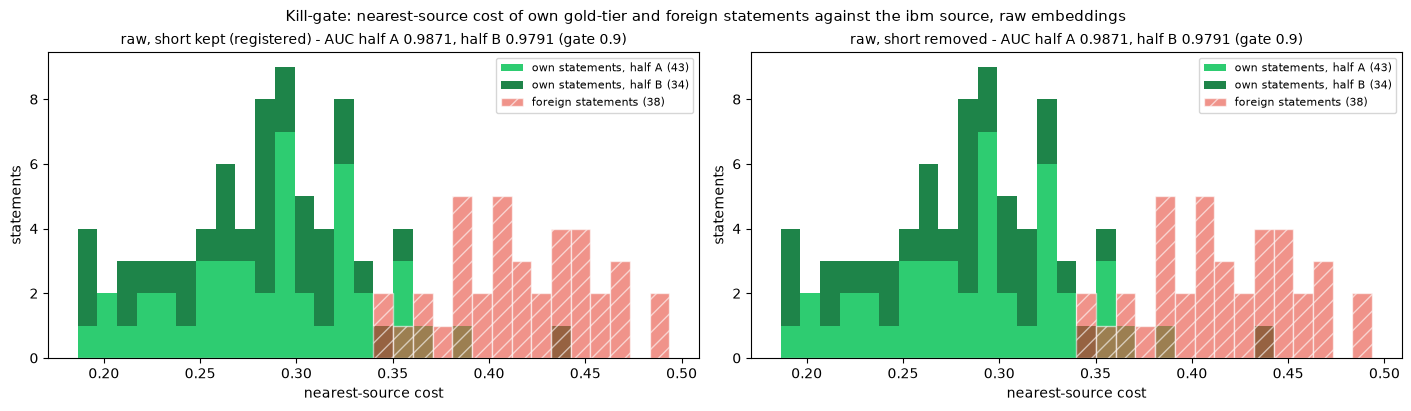

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.0), constrained_layout=True)
for ax, arm in zip(axes, RAW_ARMS):
    short = ARMS[arm]["short"]
    own = [np.concatenate([RAW_OWN[short][l] for l in HALF[half]]) for half in HALF]
    foreign = RAW_FOREIGN[short]
    bins = np.linspace(min(min(v.min() for v in own), foreign.min()), max(max(v.max() for v in own), foreign.max()), 31)
    ax.hist(own, bins=bins, stacked=True, color=[C_OWN, C_OWN_B],
            label=[f"own statements, half {half} ({len(v)})" for half, v in zip(HALF, own)])
    ax.hist(foreign, bins=bins, color=C_FOREIGN, alpha=0.6, hatch="//", edgecolor="white", label=f"foreign statements ({len(foreign)})")
    ax.set_title(f"{ARMS[arm]['label']} - AUC half A {GATE[arm]['A']:.4f}, half B {GATE[arm]['B']:.4f} (gate {GATE_AUC_MIN})", fontsize=10)
    ax.set_xlabel("nearest-source cost"); ax.set_ylabel("statements"); ax.legend(fontsize=8)
fig.suptitle("Kill-gate: nearest-source cost of own gold-tier and foreign statements against the ibm source, raw embeddings", fontsize=11)
plt.show()

**Reading** - the gate does not fire. The nearest-source cost orders own gold-tier statements below foreign statements at AUC 0.9871 on half A and 0.9791 on half B.

- **Half A** - AUC 0.9871 over 1634 pairs (43 own statements, 38 foreign statements), above the 0.90 bar
- **Half B** - AUC 0.9791 over 1292 pairs (34 own statements, 38 foreign statements), above the bar
- **Costs** - own statements read 0.2862 ± 0.0462 (half A) and 0.2800 ± 0.0519 (half B) to their nearest source statement; foreign statements read 0.4172 ± 0.0384
- **All 7 gold-tier summaries together** - AUC 0.9836, the value `E13-H73` reported for the same statements
- **Short source statements removed** - every reading is unchanged. The cause is measured: 0 of the 98 statements of the 11 summaries and 0 of the 38 foreign statements have a short source statement as their nearest source statement, so removing the 28 short statements changes no cost of these statements

## Harness check - the record's evidence numbers

The record names no sanity check. Its hypothesis cites numbers of `E13-H73` and `E14-H76`, and this notebook
reuses the `E13-H73` fixture code, so the harness is checked by reproducing those numbers: the two AUC readings
over all 11 summaries, the verbatim extract, the response of the shipped residual to the `E13-H73` insertion
doses, the movement of the mean under the `E13-H73` deletion doses, and the count of one-word source statements.
Two loops run first: the pre-pass pair costs, and the shipped residual on the insertion doses.

In [10]:
jobs = [(arm, label) for arm in PRE_ARMS for label in LABELS]
pre_own = {arm: {} for arm in PRE_ARMS}
pre_foreign = {arm: {} for arm in PRE_ARMS}
for arm, label in tqdm(jobs, desc="pre-pass pair costs (arm, host)", mininterval=15.0, file=sys.stdout):
    S = SOURCE[ARMS[arm]["short"]]
    rows = np.array([statement_costs(np.vstack([E[label], E_F[j : j + 1]]), S, "pre") for j in range(len(E_F))])
    pre_own[arm][label], pre_foreign[arm][label] = rows[:, :-1], rows[:, -1]
for arm in PRE_ARMS:
    PAIR[arm] = (pre_own[arm], pre_foreign[arm])

pre-pass pair costs (arm, host):   0%|          | 0/22 [00:00<?, ?it/s]

pre-pass pair costs (arm, host): 100%|██████████| 22/22 [00:02<00:00, 10.30it/s]

In [11]:
rng = np.random.default_rng(SEED)
# the E13-H73 draws and orders: same generator, same seed, same document order
INSERT_DRAWS = {label: [rng.choice(len(E_F), size=max(KS), replace=False) for _ in range(N_SEEDS)] for label in LABELS}
DELETE_ORDERS = {label: [rng.permutation(len(E[label])) for _ in range(N_SEEDS)] for label in LABELS}
rng_disjoint = np.random.default_rng(SEED + 1)
# disjoint reading: a held-out document receives foreign statements of the half that took no part in its calibration
DISJOINT_DRAWS = {label: [rng_disjoint.choice(FOREIGN_OF["disjoint"][HALF_OF[label]], size=max(KS), replace=False)
                          for _ in range(N_SEEDS)] for label in GOLD_TIER}
DRAWS = {"whole": INSERT_DRAWS, "disjoint": DISJOINT_DRAWS}
SHIPPED_KEYS = ("bal_pre", "bal_raw", "os_pre", "os_raw")
SHIPPED_LABEL = {"bal_pre": "shipped residual_a, default call (pre-pass on)", "bal_raw": "shipped residual_a, pre-pass off",
                 "os_pre": "mean nearest-source cost, after the pre-pass", "os_raw": "mean nearest-source cost, raw"}


def insertion_dose(label: str, draw: np.ndarray, k: int) -> np.ndarray:
    """The summary with the first k foreign statements of one draw appended"""
    return np.vstack([E[label], E_F[draw[:k]]])


def shipped_readings(X: np.ndarray, S: np.ndarray) -> tuple:
    """Shipped balanced residual_a in both pre-pass settings and the mean nearest-source cost on the same embeddings"""
    return (compute_source_conditioned(X, X, S).residual_a,
            compute_source_conditioned(X, X, S, anisotropy=False).residual_a,
            float(statement_costs(X, S, "pre").mean()),
            float(nearest_source_costs(X, S).mean()))


# SHIPPED[short][reading, document, seed, dose]; the dose k = 0 is the summary itself and is shared by the seeds
SHIPPED = {short: np.zeros((len(SHIPPED_KEYS), len(LABELS), N_SEEDS, len(INSERT_KS))) for short in SOURCE}
jobs = [(short, di, label) for short in SOURCE for di, label in enumerate(LABELS)]
for short, di, label in tqdm(jobs, desc="shipped residual on the insertion doses (source, document)", mininterval=15.0, file=sys.stdout):
    S = SOURCE[short]
    SHIPPED[short][:, di, :, 0] = np.array(shipped_readings(E[label], S))[:, None]
    for seed in range(N_SEEDS):
        for ki, k in enumerate(KS, start=1):
            SHIPPED[short][:, di, seed, ki] = shipped_readings(insertion_dose(label, INSERT_DRAWS[label][seed], k), S)

shipped residual on the insertion doses (source, document):   0%|          | 0/22 [00:00<?, ?it/s]

shipped residual on the insertion doses (source, document): 100%|██████████| 22/22 [00:08<00:00,  2.49it/s]

In [12]:
def per_document_spearman(values: np.ndarray) -> np.ndarray:
    """(document, seed, dose) values → per document, the mean over seeds of Spearman(k, value) of one trajectory"""
    ks = np.array(INSERT_KS)
    return np.array([[spearmanr(ks, values[di, seed]).statistic for seed in range(values.shape[1])]
                     for di in range(values.shape[0])]).mean(1)


def shipped(short: str, key: str) -> np.ndarray:
    """One reading of the SHIPPED block as (document, seed, dose)"""
    return SHIPPED[short][SHIPPED_KEYS.index(key)]


def deletion_ratio_of_the_mean(labels: list) -> dict:
    """E13-H73 condition (iii) on raw embeddings: median |change of the mean cost| under deletions over one insertion"""
    deltas = []
    for label in labels:
        costs = RAW_OWN["kept"][label]
        for seed in range(N_SEEDS):
            for k in KS:
                if len(costs) - k >= 1:
                    deltas.append(float(np.delete(costs, DELETE_ORDERS[label][seed][:k]).mean() - costs.mean()))
    rows = [LABELS.index(label) for label in labels]
    effect = float((shipped("kept", "os_raw")[rows, :, 1] - shipped("kept", "os_raw")[rows, :, 0]).mean())
    return {"median_abs_delta": float(np.median(np.abs(deltas))), "one_insertion_effect": effect,
            "ratio": float(np.median(np.abs(deltas))) / effect, "n_cases": len(deltas)}


X_V = E_S[0::EXTRACT_STRIDE][:EXTRACT_N]                                  # the DEF-TRANS-8 extract
EXTRACT_SHIPPED = {short: {"on": compute_source_conditioned(X_V, X_V, S), "off": compute_source_conditioned(X_V, X_V, S, anisotropy=False)}
                   for short, S in SOURCE.items()}
SPEARMAN_11 = {key: float(np.median(per_document_spearman(shipped("kept", key)))) for key in SHIPPED_KEYS}
MEAN_DELETION_11 = deletion_ratio_of_the_mean(LABELS)

measured = {
    "AUC, 98 own x 38 foreign statements, raw embeddings (E13-H73)": pair_auc("raw_kept", LABELS, ALL_FOREIGN),
    "AUC, same pairs, after the pre-pass (E13-H73)": pair_auc("pre_kept", LABELS, ALL_FOREIGN),
    "verbatim extract, closeness of the mean nearest-source cost, raw (E13-H73)": closeness(float(nearest_source_costs(X_V, E_S).mean())),
    "verbatim extract, shipped closeness_a (E13-H73)": EXTRACT_SHIPPED["kept"]["on"].closeness_a,
    "shipped residual, pre-pass off, median per-document Spearman under insertions, 11 documents (E13-H73)": SPEARMAN_11["bal_raw"],
    "mean nearest-source cost, median |change| under deletions over one insertion, raw (E13-H73)": MEAN_DELETION_11["ratio"],
    "one-word statements among the 70 ibm source statements (E14-H76)": n_one_word_source,
}
HARNESS = {name: {"measured": float(measured[name]), "registered": target, "decimals": decimals,
                  "reproduced": bool(round(float(measured[name]), decimals) == target)}
           for name, (target, decimals) in EVIDENCE.items()}
sanity_ok = all(row["reproduced"] for row in HARNESS.values())

ht = Table(title="Harness check - numbers of the record's Evidence line, reproduced with this notebook's harness", header_style="bold cyan")
for col in ("reading", "this notebook", "record", "compared at decimals", "verdict"):
    ht.add_column(col, justify="left" if col in ("reading", "verdict") else "right")
for name, row in HARNESS.items():
    ht.add_row(name, f"{row['measured']:.{6 if row['decimals'] else 0}f}", f"{row['registered']:.{row['decimals']}f}", str(row["decimals"]),
               "[green]reproduced[/green]" if row["reproduced"] else "[red]DIFFERS[/red]")
console.print(Group(
    ht,
    "all seven numbers are read with the short source statements kept, the source reading of E13-H73 and E14-H76",
    f"also read: shipped residual, default call, median per-document Spearman over the 11 documents {SPEARMAN_11['bal_pre']:.4f} "
    f"(E13-H73 result: -0.8429); DEF-TRANS-8 on the extract: residual_a {EXTRACT_SHIPPED['kept']['on'].residual_a:.6f}, "
    f"closeness_a {EXTRACT_SHIPPED['kept']['on'].closeness_a:.6f}",
    f"[bold {'green' if sanity_ok else 'red'}]HARNESS CHECK: {'PASSED' if sanity_ok else 'FAILED'} - "
    f"{sum(row['reproduced'] for row in HARNESS.values())} of {len(HARNESS)} numbers reproduced[/]",
))

                                    Harness check - numbers of the record's Evidence line, reproduced with this notebook's harness                                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ reading                                                                                               ┃ this notebook ┃  record ┃ compared at decimals ┃ verdict    ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ AUC, 98 own x 38 foreign statements, raw embeddings (E13-H73)                                         │      0.966971 │  0.9670 │                    4 │ reproduced │
│ AUC, same pairs, after the pre-pass (E13-H73)                                                         │      0.788937 │  0.7889 │                    4 │ reproduced │
│ verbatim extract, closeness of the mean nearest-source cost, raw (E13-H73)                            │      0.999917 │  0.9999 │                    4 │ reproduced │
│ verbatim extract, shipped closeness_a (E13-H73)                                                       │      0.322442 │  0.3224 │                    4 │ reproduced │
│ shipped residual, pre-pass off, median per-document Spearman under insertions, 11 documents (E13-H73) │     -0.257143 │ -0.2571 │                    4 │ reproduced │
│ mean nearest-source cost, median |change| under deletions over one insertion, raw (E13-H73)           │      0.340866 │   0.341 │                    3 │ reproduced │
│ one-word statements among the 70 ibm source statements (E14-H76)                                      │            22 │      22 │                    0 │ reproduced │
└───────────────────────────────────────────────────────────────────────────────────────────────────────┴───────────────┴─────────┴──────────────────────┴────────────┘
all seven numbers are read with the short source statements kept, the source reading of E13-H73 and E14-H76
also read: shipped residual, default call, median per-document Spearman over the 11 documents -0.8429 (E13-H73 result: -0.8429); DEF-TRANS-8 on the extract: residual_a 0.958211, 
closeness_a 0.322442
HARNESS CHECK: PASSED - 7 of 7 numbers reproduced

**Reading** - the harness reproduces all seven numbers of the record's Evidence line at the decimals the record prints.

- **AUC over the 11 summaries** - 0.966971 on raw embeddings and 0.788937 after the pre-pass, against 0.9670 and 0.7889
- **Verbatim extract** - closeness 0.999917 for the mean nearest-source cost and 0.322442 for the shipped `closeness_a`, against 0.9999 and 0.3224
- **Shipped residual under the `E13-H73` insertion doses** - median per-document Spearman -0.257143 with the pre-pass off, against -0.2571; the default call reads -0.8429, also the `E13-H73` value
- **Mean cost under the `E13-H73` deletion doses** - median |change| 0.340866 of one insertion, against 34.1%
- **One-word source statements** - 22 of 70, the `E14-H76` count
- **Consequence** - the fixture, the encoder output and the dose draws of this notebook are those of `E13-H73`

## Registered experiment

The three clauses of the acceptance bar, each read on all four arms and on both foreign readings. The registered
reading is the arm `raw, short kept` with the foreign set whole.

- **clause (1)** - the cutoff is chosen on one half of the gold-tier documents and the flag is scored on the other half, in both directions
- **clause (2)** - the count of the verbatim extract `source[0::7][:10]` under each of the two cutoffs
- **clause (3)** - the mean of the two cutoffs, not refitted, on the second source article

### Clause (1) - cutoff on the calibration half, balanced accuracy on the held-out half

The cutoff rule runs on the own statements of the calibration half and the foreign statements paired with that
half. The scored set is the own statements of the other half and the foreign statements paired with it. In the
whole reading both halves are paired with all 38 foreign statements; in the disjoint reading with 19 each.

In [13]:
def clause_one(arm: str, foreign_reading: str) -> dict:
    """Cutoff on the calibration half and the flag's balanced accuracy on the held-out half, both directions"""
    directions = {}
    for name, (cal, held) in DIRECTIONS.items():
        fsel_cal, fsel_held = FOREIGN_OF[foreign_reading][cal], FOREIGN_OF[foreign_reading][held]
        own_held, foreign_held = pooled(arm, HALF[held], fsel_held)
        fit = calibrate(*pooled(arm, HALF[cal], fsel_cal))
        over_run = [balanced_accuracy(own_held, foreign_held, c)["ba"] for c in GRID[(GRID >= fit["run_lo"]) & (GRID <= fit["run_hi"])]]
        directions[name] = {
            **fit,
            "calibration_auc": pair_auc(arm, HALF[cal], fsel_cal),
            "held_auc": pair_auc(arm, HALF[held], fsel_held),
            "held": balanced_accuracy(own_held, foreign_held, fit["cutoff"]),
            "held_ba_over_run": (min(over_run), max(over_run)),
            "held_counts": flag_counts(arm, HALF[held], fsel_held, fit["cutoff"]),
            "n_foreign_calibration": int(len(fsel_cal)), "n_foreign_held": int(len(fsel_held)),
        }
    return {"directions": directions, "mean_cutoff": round(float(np.mean([d["cutoff"] for d in directions.values()])), 5)}


def errors_below_bar(direction: dict) -> int:
    """Smallest number of further wrongly flagged statements that brings a held-out balanced accuracy below the bar"""
    own_flagged, n_own, foreign_flagged, n_foreign = direction["held_counts"]
    for total in range(1, n_own + n_foreign + 1):
        for own_errors in range(min(total, n_own - own_flagged) + 1):
            foreign_errors = total - own_errors
            if foreign_errors <= foreign_flagged:
                ba = ((foreign_flagged - foreign_errors) / n_foreign + (n_own - own_flagged - own_errors) / n_own) / 2
                if ba < BAR_HELD_BA:
                    return total
    return n_own + n_foreign


CAL = {arm: {fr: clause_one(arm, fr) for fr in FOREIGN_READINGS} for arm in ARMS}
STEP = {name: {"one_own_statement": 1 / (2 * d["held_counts"][1]), "one_foreign_statement": 1 / (2 * d["held_counts"][3]),
               "errors_below_bar": errors_below_bar(d)}
        for name, d in CAL[VERDICT_ARM][VERDICT_FOREIGN]["directions"].items()}

ct = Table(title="Clause (1) - cutoff chosen on the calibration half, flag scored on the held-out half", header_style="bold cyan")
for col in ("arm", "foreign reading", "direction", "calibration AUC", "cutoff", "run at the maximum (grid points)", "calibration BA",
            "held-out BA", f"bar >= {BAR_HELD_BA}", "TPR (foreign flagged)", "TNR (own not flagged)", "held-out BA over the run, min / max"):
    ct.add_column(col, justify="left" if col in ("arm", "foreign reading", "direction") else "right")
for arm in ARMS:
    for fr in FOREIGN_READINGS:
        for name, d in CAL[arm][fr]["directions"].items():
            own_flagged, n_own, foreign_flagged, n_foreign = d["held_counts"]
            unit = "" if ARMS[arm]["embedding"] == "raw" else " calls"
            ct.add_row(ARMS[arm]["label"], FOREIGN_READINGS[fr], name, f"{d['calibration_auc']:.4f}", f"{d['cutoff']:.4f}",
                       f"{d['run_lo']:.3f} to {d['run_hi']:.3f} ({d['run_points']})", f"{d['calibration_ba']:.4f}",
                       f"{d['held']['ba']:.4f}", mark(d["held"]["ba"] >= BAR_HELD_BA),
                       f"{d['held']['tpr']:.4f} ({foreign_flagged}/{n_foreign}{unit})",
                       f"{d['held']['tnr']:.4f} ({n_own - own_flagged}/{n_own}{unit})",
                       f"{d['held_ba_over_run'][0]:.4f} / {d['held_ba_over_run'][1]:.4f}",
                       style="bold" if (arm, fr) == (VERDICT_ARM, VERDICT_FOREIGN) else None)
console.print(Group(
    ct,
    "mean of the two cutoffs per arm and foreign reading: "
    + "; ".join(f"{ARMS[arm]['label']}, {fr}: {CAL[arm][fr]['mean_cutoff']:.5f}" for arm in ARMS for fr in FOREIGN_READINGS),
    "counts in brackets: statements on the raw arms; (host summary, foreign statement) calls on the pre-pass arms",
    "registered reading, size of one statement: "
    + "; ".join(f"{name}: one own statement moves the held-out balanced accuracy by {x['one_own_statement']:.4f}, one foreign statement by "
                f"{x['one_foreign_statement']:.4f}, {x['errors_below_bar']} further wrong flags bring it below {BAR_HELD_BA}"
                for name, x in STEP.items()),
))

                                                Clause (1) - cutoff chosen on the calibration half, flag scored on the held-out half                                                
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃               ┃               ┃           ┃                ┃        ┃    run at the ┃                ┃             ┃            ┃               ┃                ┃   held-out BA ┃
┃               ┃ foreign       ┃           ┃    calibration ┃        ┃ maximum (grid ┃                ┃             ┃            ┃  TPR (foreign ┃   TNR (own not ┃ over the run, ┃
┃ arm           ┃ reading       ┃ direction ┃            AUC ┃ cutoff ┃       points) ┃ calibration BA ┃ held-out BA ┃ bar >= 0.9 ┃      flagged) ┃       flagged) ┃     min / max ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ raw, short    │ foreign set   │ A→B       │         0.9871 │ 0.3375 │      0.335 to │         0.9419 │      0.9412 │        met │        1.0000 │ 0.8824 (30/34) │      0.9412 / │
│ kept          │ whole         │           │                │        │     0.340 (2) │                │             │            │       (38/38) │                │        0.9559 │
│ (registered)  │ (registered)  │           │                │        │               │                │             │            │               │                │               │
│ raw, short    │ foreign set   │ B→A       │         0.9791 │ 0.3550 │      0.355 to │         0.9590 │      0.9272 │        met │        0.9474 │ 0.9070 (39/43) │      0.9272 / │
│ kept          │ whole         │           │                │        │     0.355 (1) │                │             │            │       (36/38) │                │        0.9272 │
│ (registered)  │ (registered)  │           │                │        │               │                │             │            │               │                │               │
│ raw, short    │ foreign set   │ A→B       │         0.9878 │ 0.3425 │      0.335 to │         0.9419 │      0.9559 │        met │        1.0000 │ 0.9118 (31/34) │      0.9296 / │
│ kept          │ in disjoint   │           │                │        │     0.350 (4) │                │             │            │       (19/19) │                │        0.9559 │
│ (registered)  │ halves        │           │                │        │               │                │             │            │               │                │               │
│ raw, short    │ foreign set   │ B→A       │         0.9752 │ 0.3575 │      0.355 to │         0.9590 │      0.9125 │        met │        0.8947 │ 0.9302 (40/43) │      0.9241 / │
│ kept          │ in disjoint   │           │                │        │     0.360 (2) │                │             │            │       (17/19) │                │        0.9272 │
│ (registered)  │ halves        │           │                │        │               │                │             │            │               │                │               │
│ raw, short    │ foreign set   │ A→B       │         0.9871 │ 0.3375 │      0.335 to │         0.9419 │      0.9412 │        met │        1.0000 │ 0.8824 (30/34) │      0.9412 / │
│ removed       │ whole         │           │                │        │     0.340 (2) │                │             │            │       (38/38) │                │        0.9559 │
│               │ (registered)  │           │                │        │               │                │             │            │               │                │               │
│ raw, short    │ foreign set   │ B→A       │         0.9791 │ 0.3550 │      0.355 to │         0.9590 │      0.9272 │        met │        0.9474 │ 0.9070 (39/43) │      0.9272 / │
│ removed       │ 

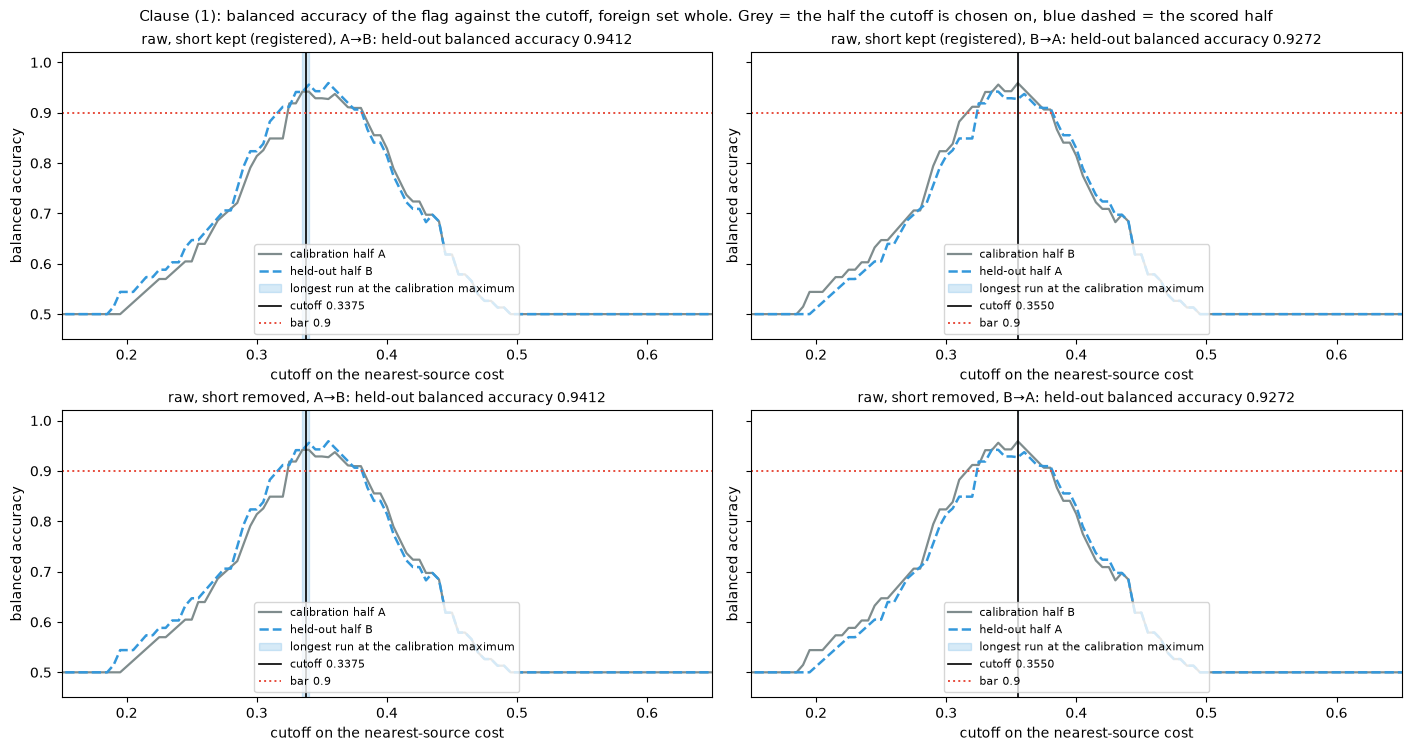

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.4), constrained_layout=True, sharey=True)
for row, arm in enumerate(RAW_ARMS):
    for col, (name, (cal, held)) in enumerate(DIRECTIONS.items()):
        ax, fit = axes[row, col], CAL[arm]["whole"]["directions"][name]
        ax.plot(GRID, ba_curve(*pooled(arm, HALF[cal], ALL_FOREIGN)), color=C_BASELINE, lw=1.6, label=f"calibration half {cal}")
        ax.plot(GRID, ba_curve(*pooled(arm, HALF[held], ALL_FOREIGN)), color=C_LEVER, lw=1.8, ls="--", label=f"held-out half {held}")
        ax.axvspan(fit["run_lo"], fit["run_hi"], color=C_LEVER, alpha=0.2, label="longest run at the calibration maximum")
        ax.axvline(fit["cutoff"], color="black", lw=1.2, label=f"cutoff {fit['cutoff']:.4f}")
        ax.axhline(BAR_HELD_BA, color=C_FOREIGN, ls=":", lw=1.4, label=f"bar {BAR_HELD_BA}")
        ax.set_xlim(0.15, 0.65); ax.set_ylim(0.45, 1.02)
        ax.set_title(f"{ARMS[arm]['label']}, {name}: held-out balanced accuracy {fit['held']['ba']:.4f}", fontsize=10)
        ax.set_xlabel("cutoff on the nearest-source cost"); ax.set_ylabel("balanced accuracy"); ax.legend(fontsize=8, loc="lower center")
fig.suptitle("Clause (1): balanced accuracy of the flag against the cutoff, foreign set whole. Grey = the half the cutoff is chosen on, "
             "blue dashed = the scored half", fontsize=11)
plt.show()

**Reading** - clause (1) is met on the registered arm: the flag reads a held-out balanced accuracy of 0.9412 and 0.9272, both above 0.90. It is also met with the foreign set in disjoint halves. It is not met after the pre-pass.

- **A→B** - cutoff 0.3375, the midpoint of a run of 2 grid points (0.335 to 0.340) at the calibration maximum 0.9419. On half B the flag marks 38 of 38 foreign statements and 4 of 34 own statements: balanced accuracy 0.9412
- **B→A** - cutoff 0.3550, one grid point at the calibration maximum 0.9590. On half A the flag marks 36 of 38 foreign statements and 4 of 43 own statements: balanced accuracy 0.9272
- **Tie rule** - over the grid points of the A→B run the held-out reading lies between 0.9412 and 0.9559; the B→A run has one point. The executor's midpoint rule does not decide the clause
- **Foreign set in disjoint halves** - cutoffs 0.3425 and 0.3575, held-out balanced accuracy 0.9559 (19 of 19 foreign statements flagged, 31 of 34 own statements not flagged) and 0.9125 (17 of 19 and 40 of 43). Both are above 0.90, so the clause does not depend on the scored foreign statements having taken part in the calibration
- **Size of one statement** - one own statement moves the held-out reading by 0.0147 (A→B) or 0.0116 (B→A), one foreign statement by 0.0132. In each direction 3 further wrong flags bring the reading below 0.90
- **Short source statements removed** - identical to the registered arm in every column, for the cause measured in the kill-gate section
- **After the pre-pass** - calibration AUC 0.8097 and 0.8382; held-out balanced accuracy 0.8168 and 0.7277 with the short source statements kept, 0.8386 and 0.7967 with them removed. No pre-pass row reaches 0.90
- **The two cutoffs** - 0.3375 from half A and 0.3550 from half B. Their mean, 0.34625, is the cutoff of clause (3)

### Clause (2) - the verbatim extract

Ten statements copied from the 70-statement ibm source, `source[0::7][:10]`, the extract of defect `DEF-TRANS-8`.
The count is read under each of the two cutoffs of the arm and under their mean. With the short source statements
kept, every extract statement is a row of the source. With them removed, an extract statement of fewer than 5
words has no copy in the source.

In [15]:
EXTRACT_IS_SHORT = ~KEEP_S[0::EXTRACT_STRIDE][:EXTRACT_N]
EXTRACT_SHORT_TEXTS = [t for t, short in zip(S_TEXTS[0::EXTRACT_STRIDE][:EXTRACT_N], EXTRACT_IS_SHORT) if short]
EXTRACT_COSTS = {arm: statement_costs(X_V, SOURCE[spec["short"]], spec["embedding"]) for arm, spec in ARMS.items()}


def extract_reading(arm: str, foreign_reading: str) -> dict:
    """Flagged statements of the extract under each calibrated cutoff of the arm and under the mean cutoff"""
    cal = CAL[arm][foreign_reading]
    cutoffs = {name: d["cutoff"] for name, d in cal["directions"].items()} | {"mean": cal["mean_cutoff"]}
    flagged = {name: EXTRACT_COSTS[arm] > c for name, c in cutoffs.items()}
    return {"flagged": {name: int(f.sum()) for name, f in flagged.items()},
            "flagged_short": {name: int((f & EXTRACT_IS_SHORT).sum()) for name, f in flagged.items()},
            "max_cost": float(EXTRACT_COSTS[arm].max()),
            "max_cost_long_statements": float(EXTRACT_COSTS[arm][~EXTRACT_IS_SHORT].max())}


EXTRACT = {arm: {fr: extract_reading(arm, fr) for fr in FOREIGN_READINGS} for arm in ARMS}

et = Table(title=f"Clause (2) - flagged statements of the verbatim extract source[0::{EXTRACT_STRIDE}][:{EXTRACT_N}] "
                 f"({int(EXTRACT_IS_SHORT.sum())} of its {EXTRACT_N} statements have fewer than {MIN_WORDS} words)", header_style="bold cyan")
for col in ("arm", "foreign reading", *[f"flagged, cutoff {name}" for name in DIRECTIONS], "flagged, mean cutoff", f"bar = {BAR_EXTRACT_FLAGGED}",
            "of the flagged, under 5 words", "highest cost of the 10", "highest cost, statements of 5+ words"):
    et.add_column(col, justify="left" if col in ("arm", "foreign reading") else "right")
for arm in ARMS:
    for fr in FOREIGN_READINGS:
        x = EXTRACT[arm][fr]
        et.add_row(ARMS[arm]["label"], FOREIGN_READINGS[fr], *[f"{x['flagged'][name]}/{EXTRACT_N}" for name in DIRECTIONS],
                   f"{x['flagged']['mean']}/{EXTRACT_N}", mark(all(x["flagged"][name] == BAR_EXTRACT_FLAGGED for name in DIRECTIONS)),
                   " / ".join(str(x["flagged_short"][name]) for name in DIRECTIONS), f"{x['max_cost']:.6f}", f"{x['max_cost_long_statements']:.6f}",
                   style="bold" if (arm, fr) == (VERDICT_ARM, VERDICT_FOREIGN) else None)
console.print(Group(
    et,
    f"extract statements of fewer than {MIN_WORDS} words: " + escape(repr(EXTRACT_SHORT_TEXTS)),
    "baseline on the same extract, shipped compute_source_conditioned: "
    + "; ".join(f"short {short}: residual_a {r['on'].residual_a:.4f} and closeness_a {r['on'].closeness_a:.4f} (default call), "
                f"residual_a {r['off'].residual_a:.4f} and closeness_a {r['off'].closeness_a:.4f} (pre-pass off)"
                for short, r in EXTRACT_SHIPPED.items()),
))

                             Clause (2) - flagged statements of the verbatim extract source[0::7][:10] (1 of its 10 statements have fewer than 5 words)                             
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃                    ┃                    ┃                    ┃                    ┃                    ┃         ┃                    ┃                     ┃      highest cost, ┃
┃                    ┃                    ┃    flagged, cutoff ┃    flagged, cutoff ┃      flagged, mean ┃         ┃    of the flagged, ┃ highest cost of the ┃   statements of 5+ ┃
┃ arm                ┃ foreign reading    ┃                A→B ┃                B→A ┃             cutoff ┃ bar = 0 ┃      under 5 words ┃                  10 ┃              words ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ raw, short kept    │ foreign set whole  │               0/10 │               0/10 │               0/10 │     met │              0 / 0 │            0.000691 │           0.000691 │
│ (registered)       │ (registered)       │                    │                    │                    │         │                    │                     │                    │
│ raw, short kept    │ foreign set in     │               0/10 │               0/10 │               0/10 │     met │              0 / 0 │            0.000691 │           0.000691 │
│ (registered)       │ disjoint halves    │                    │                    │                    │         │                    │                     │                    │
│ raw, short removed │ foreign set whole  │               1/10 │               1/10 │               1/10 │ not met │              1 / 1 │            1.161591 │           0.000691 │
│                    │ (registered)       │                    │                    │                    │         │                    │                     │                    │
│ raw, short removed │ foreign set in     │               1/10 │               1/10 │               1/10 │ not met │              1 / 1 │            1.161591 │           0.000691 │
│                    │ disjoint halves    │                    │                    │                    │         │                    │                     │                    │
│ pre-pass, short    │ foreign set whole  │               0/10 │               0/10 │               0/10 │     met │              0 / 0 │            0.000691 │           0.000691 │
│ kept               │ (registered)       │                    │                    │                    │         │                    │                     │                    │
│ pre-pass, short    │ foreign set in     │               0/10 │               0/10 │               0/10 │     met │              0 / 0 │            0.000691 │           0.000691 │
│ kept               │ disjoint halves    │                    │                    │                    │         │                    │                     │                    │
│ pre-pass, short    │ foreign set whole  │               0/10 │               0/10 │               0/10 │     met │              0 / 0 │            1.040443 │           0.000691 │
│ removed            │ (registered)       │                    │                    │                    │         │                    │                     │                    │
│ pre-pass, short    │ foreign set in     │               0/10 │               0/10 │               0/10 │     met │              0 / 0 │            1.040443 │           0.000691 │
│ removed            │ disjoint halves    │                    │                    │                    │         │                    │                     │                    │
└─────────────────

**Reading** - clause (2) is met on the registered arm and holds there by construction. It is not met when the short source statements are removed.

- **Registered arm** - 0 of 10 flagged under both cutoffs and under their mean. The highest cost of the 10 statements is 0.000691: each extract statement is a statement of the source, so its nearest-source cost is zero up to float32 rounding. No cutoff of the grid above 0.000 flags such a statement, so the clause cannot fail on this arm
- **Short source statements removed** - 1 of 10 flagged under both cutoffs. The flagged statement is the one extract statement of fewer than 5 words, `###`. It has no copy in the filtered source and reads 1.161591; the 9 statements of 5 words or more read at most 0.000691
- **Consequence for a build** - the document and the source have to pass the same statement filter. With a filter on the source only, a markup statement of the document has no counterpart in the source and is flagged
- **After the pre-pass** - 0 of 10 with the short statements kept. With them removed the `###` statement reads 1.040443, below that arm's cutoffs 1.1350 and 1.1450, so it is not flagged
- **Baseline** - the shipped balanced residual of the same extract reads `residual_a` 0.9582 and `closeness_a` 0.3224 on the default call, the reading of defect `DEF-TRANS-8`, and 0.5172 and 0.6343 with the pre-pass off

### Clause (3) - the second source article, mean cutoff, no refit

The roles of the two articles are exchanged: the wergeland article is the source, the statements of its sections
`werg-a`, `werg-b`, `werg-c` are the own statements, and the 77 statements of the 7 gold-tier ibm summaries are
the foreign statements. The cutoff is the mean of the two cutoffs of the arm and is not refitted. The registered
reading uses the source as the shipped default reader returns it and the section statements; the back-translated
statements are the second reading, because they are not copies of source statements.

In [16]:
def second_article(arm: str, comment: str, own_keys: list) -> dict:
    """The flag on the second source: own = wergeland statements, foreign = gold-tier ibm statements, mean cutoff of the arm"""
    spec = ARMS[arm]
    S2 = SECOND_SOURCE[(comment, spec["short"])]
    own = np.concatenate([statement_costs(E_WERG[key], S2, spec["embedding"]) for key in own_keys])
    foreign = np.concatenate([statement_costs(E[label], S2, spec["embedding"]) for label in GOLD_TIER])
    out = {"own": own, "foreign": foreign, "auc": auc_of(own, foreign), "own_max": float(own.max()), "own_median": float(np.median(own)),
           "foreign_min": float(foreign.min())}
    for fr in FOREIGN_READINGS:
        cutoff = CAL[arm][fr]["mean_cutoff"]
        out[fr] = {"cutoff": cutoff, **balanced_accuracy(own, foreign, cutoff),
                   "own_flagged": int((own > cutoff).sum()), "foreign_flagged": int((foreign > cutoff).sum())}
    return out


SECOND = {arm: {(comment, own_name): second_article(arm, comment, keys) for comment in COMMENTS for own_name, keys in OWN_SETS.items()}
          for arm in ARMS}

s2 = Table(title="Clause (3) - second source article (wergeland), mean of the two cutoffs, no refit", header_style="bold cyan")
for col in ("arm", "source", "own statements", "AUC", "mean cutoff, whole", "BA", f"bar >= {BAR_SECOND_BA}", "TPR (ibm flagged)",
            "TNR (wergeland not flagged)", "own cost, median / highest", "lowest ibm cost", "disjoint: mean cutoff / BA"):
    s2.add_column(col, justify="left" if col in ("arm", "source", "own statements") else "right", overflow="fold")
for arm in ARMS:
    for (comment, own_name), x in SECOND[arm].items():
        w, d = x["whole"], x["disjoint"]
        registered = (comment, own_name) == REGISTERED_SECOND
        s2.add_row(ARMS[arm]["label"], f"{comment}, short {ARMS[arm]['short']}", own_name, f"{x['auc']:.4f}", f"{w['cutoff']:.5f}", f"{w['ba']:.4f}",
                   mark(w["ba"] >= BAR_SECOND_BA), f"{w['tpr']:.4f} ({w['foreign_flagged']}/{len(x['foreign'])})",
                   f"{w['tnr']:.4f} ({len(x['own']) - w['own_flagged']}/{len(x['own'])})", f"{x['own_median']:.4f} / {x['own_max']:.4f}",
                   f"{x['foreign_min']:.4f}", f"{d['cutoff']:.5f} / {d['ba']:.4f}", style="bold" if registered and arm == VERDICT_ARM else None)

# the flagged own statements of the registered arm, and which second-source statement is the nearest one
registered_cutoff = CAL[VERDICT_ARM][VERDICT_FOREIGN]["mean_cutoff"]
flagged_own_lines = []
for own_name, keys in OWN_SETS.items():
    costs = SECOND[VERDICT_ARM][("comment kept", own_name)]["own"]
    texts = [t for key in keys for t in WERG_TEXTS[key]]
    flagged_own_lines += [f"flagged own statement, {own_name}, cost {c:.4f}: " + escape(repr(t))
                          for t, c in zip(texts, costs) if c > registered_cutoff]
comment_removed_texts = {squeeze(t) for t in W_TEXTS}
W2_COMMENT = np.array([squeeze(t) not in comment_removed_texts for t in W2_TEXTS])       # absent from the comment-removed segmentation
w2_special = W2_COMMENT | ~KEEP_W2
nearest_special = {name: int(sum(w2_special[cost_matrix(emb, E_W2).argmin(1)].sum() for emb in embs)) for name, embs in (
    ("section statements", [E_WERG[key] for key in OWN_SETS["sections"]]),
    ("back-translated statements", [E_WERG[key] for key in OWN_SETS["back-translations"]]),
    ("gold-tier ibm statements", [E[label] for label in GOLD_TIER]))}
console.print(Group(
    s2,
    *flagged_own_lines,
    f"second source through the shipped reader: {int(W2_COMMENT.sum())} of {len(W2_TEXTS)} statements are absent from the comment-removed "
    f"segmentation, {int((~KEEP_W2).sum())} have fewer than {MIN_WORDS} words, {int(w2_special.sum())} are one or the other; statements whose "
    "nearest second-source statement is one of them: " + ", ".join(f"{n} {name}" for name, n in nearest_special.items()),
))

                                                 Clause (3) - second source article (wergeland), mean of the two cutoffs, no refit                                                  
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃               ┃               ┃               ┃        ┃               ┃        ┃             ┃                ┃           TNR ┃      own cost, ┃               ┃                ┃
┃               ┃               ┃ own           ┃        ┃  mean cutoff, ┃        ┃             ┃       TPR (ibm ┃    (wergeland ┃       median / ┃    lowest ibm ┃ disjoint: mean ┃
┃ arm           ┃ source        ┃ statements    ┃    AUC ┃         whole ┃     BA ┃ bar >= 0.85 ┃       flagged) ┃  not flagged) ┃        highest ┃          cost ┃    cutoff / BA ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ raw, short    │ comment kept, │ sections      │ 0.9768 │       0.34625 │ 0.9868 │         met │ 1.0000 (77/77) │        0.9737 │       0.0000 / │        0.3983 │      0.35000 / │
│ kept          │ short kept    │               │        │               │        │             │                │       (37/38) │         0.5083 │               │         0.9868 │
│ (registered)  │               │               │        │               │        │             │                │               │                │               │                │
│ raw, short    │ comment kept, │ back-translat │ 0.9761 │       0.34625 │ 0.9868 │         met │ 1.0000 (77/77) │        0.9737 │       0.1486 / │        0.3983 │      0.35000 / │
│ kept          │ short kept    │ ions          │        │               │        │             │                │       (37/38) │         0.5392 │               │         0.9868 │
│ (registered)  │               │               │        │               │        │             │                │               │                │               │                │
│ raw, short    │ comment       │ sections      │ 0.9768 │       0.34625 │ 0.9868 │         met │ 1.0000 (77/77) │        0.9737 │       0.0000 / │        0.3983 │      0.35000 / │
│ kept          │ removed,      │               │        │               │        │             │                │       (37/38) │         0.5083 │               │         0.9868 │
│ (registered)  │ short kept    │               │        │               │        │             │                │               │                │               │                │
│ raw, short    │ comment       │ back-translat │ 0.9761 │       0.34625 │ 0.9868 │         met │ 1.0000 (77/77) │        0.9737 │       0.1486 / │        0.3983 │      0.35000 / │
│ kept          │ removed,      │ ions          │        │               │        │             │                │       (37/38) │         0.5392 │               │         0.9868 │
│ (registered)  │ short kept    │               │        │               │        │             │                │               │                │               │                │
│ raw, short    │ comment kept, │ sections      │ 0.9768 │       0.34625 │ 0.9868 │         met │ 1.0000 (77/77) │        0.9737 │       0.0000 / │        0.3983 │      0.35000 / │
│ removed       │ short removed │               │        │               │        │             │                │       (37/38) │         0.5083 │               │         0.9868 │
│ raw, short    │ comment kept, │ back-translat │ 0.9761 │       0.34625 │ 0.9868 │         met │ 1.0000 (77/77) │        0.9737 │       0.1486 / │        0.3983 │      0.35000 / │
│ removed       │ short removed │ ions          │        │               │        │             │                │       (37/38) │         0.5392 │               │         0.9868 │
│ raw, short    │ 

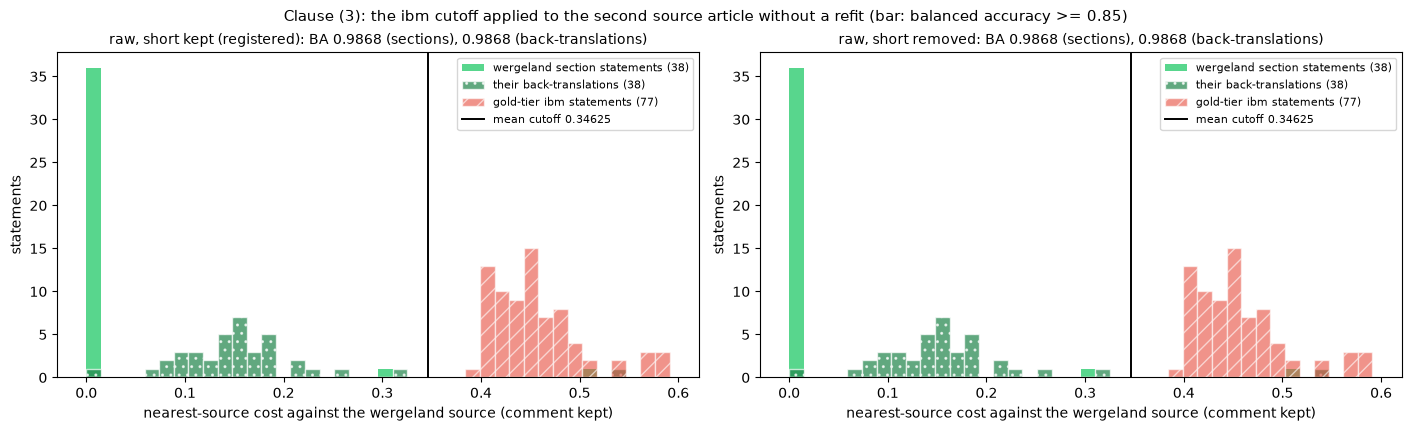

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
for ax, arm in zip(axes, RAW_ARMS):
    sections = SECOND[arm][REGISTERED_SECOND]
    back = SECOND[arm][("comment kept", "back-translations")]
    bins = np.linspace(0.0, max(sections["foreign"].max(), back["own"].max()) * 1.02, 41)
    ax.hist(sections["own"], bins=bins, color=C_OWN, alpha=0.8, label=f"wergeland section statements ({len(sections['own'])})")
    ax.hist(back["own"], bins=bins, color=C_OWN_B, alpha=0.7, hatch="..", edgecolor="white",
            label=f"their back-translations ({len(back['own'])})")
    ax.hist(sections["foreign"], bins=bins, color=C_FOREIGN, alpha=0.6, hatch="//", edgecolor="white",
            label=f"gold-tier ibm statements ({len(sections['foreign'])})")
    cutoff = sections["whole"]["cutoff"]
    ax.axvline(cutoff, color="black", lw=1.4, label=f"mean cutoff {cutoff:.5f}")
    ax.set_title(f"{ARMS[arm]['label']}: BA {sections['whole']['ba']:.4f} (sections), {back['whole']['ba']:.4f} (back-translations)",
                 fontsize=10)
    ax.set_xlabel("nearest-source cost against the wergeland source (comment kept)"); ax.set_ylabel("statements"); ax.legend(fontsize=8)
fig.suptitle(f"Clause (3): the ibm cutoff applied to the second source article without a refit (bar: balanced accuracy >= {BAR_SECOND_BA})",
             fontsize=11)
plt.show()

**Reading** - clause (3) is met: with the mean cutoff 0.34625 and no refit the flag reads a balanced accuracy of 0.9868 on the second source article, above 0.85. The own side of that reading is close to 1 by construction; the foreign side could have failed and did not.

- **Foreign side** - 77 of 77 gold-tier ibm statements are flagged against the wergeland source. Their lowest cost is 0.3983, against the cutoff 0.34625
- **Own side, section statements** - 37 of 38 are not flagged. 36 of the 38 section statements are statements of the second source verbatim, and their median cost is 0.0000, so this side is not a test of the flag
- **Own side, back-translations** - the second reading, where the own statements are not copies: 1 of the 38 back-translated statements is a statement of the source verbatim, their median cost is 0.1486, and 37 of 38 are not flagged. The balanced accuracy is 0.9868 again
- **The one flagged own statement** - `Students need to understand the possibilities` reads 0.5083, and its back-translation `Students must understand the possibilities` reads 0.5392. It is a 6-word statement of the structure fixture that the second source does not hold as a statement
- **Source reading rules** - with the HTML provenance comment removed, with the short statements removed, and with both, the raw readings are identical. The cause is measured: 0 section statements, 0 back-translated statements and 0 ibm statements have one of those 14 source statements as their nearest one
- **Cutoff of the disjoint reading** - 0.35000 gives the same 0.9868
- **After the pre-pass** - 0.9803 with the short statements kept and 0.9544 with them removed, AUC 0.9945 and 0.9979. In this clause each document is one pre-pass call against the second source; in clause (1) one foreign statement is read inside an own document. The pre-pass arms meet clause (3) and fail clause (1). Which property of the pooled statements causes the difference was not measured
- **Above the predicted interval** - the record predicted 0.85 to 0.95; the reading is 0.9868

### Acceptance bar

The record's bar, applied to each arm and each foreign reading: held-out balanced accuracy at or above 0.90 in
both directions AND 0 flagged statements of the verbatim extract under both cutoffs AND second-article balanced
accuracy at or above 0.85 at the mean cutoff. The verdict is read on the row `raw, short kept`, foreign set whole.

In [18]:
def bar_reading(arm: str, foreign_reading: str) -> dict:
    """The three clauses of the record for one arm and one foreign reading"""
    cal = CAL[arm][foreign_reading]
    held = {name: d["held"]["ba"] for name, d in cal["directions"].items()}
    extract = {name: EXTRACT[arm][foreign_reading]["flagged"][name] for name in DIRECTIONS}
    second = SECOND[arm][REGISTERED_SECOND][foreign_reading]
    clauses = {
        "clause_1_met": bool(all(v >= BAR_HELD_BA for v in held.values())),
        "clause_2_met": bool(all(n == BAR_EXTRACT_FLAGGED for n in extract.values())),
        "clause_3_met": bool(second["ba"] >= BAR_SECOND_BA),
    }
    return {"held_ba": held, "held_ba_min": min(held.values()), "extract_flagged": extract, "second_ba": second["ba"],
            "second_ba_back_translations": SECOND[arm][("comment kept", "back-translations")][foreign_reading]["ba"],
            "cutoffs": {name: d["cutoff"] for name, d in cal["directions"].items()}, "mean_cutoff": cal["mean_cutoff"],
            **clauses, "met": all(clauses.values())}


BAR = {arm: {fr: bar_reading(arm, fr) for fr in FOREIGN_READINGS} for arm in ARMS}

bt = Table(title="Acceptance bar per arm and foreign reading - the record's three clauses", header_style="bold cyan")
for col in ("arm", "foreign reading", "cutoffs A→B / B→A", f"(1) held-out BA A→B / B→A >= {BAR_HELD_BA}",
            f"(2) extract flagged = {BAR_EXTRACT_FLAGGED}", f"(3) second-article BA >= {BAR_SECOND_BA}",
            "second-article BA, back-translations (not the bar)", "bar"):
    bt.add_column(col, justify="left" if col in ("arm", "foreign reading") else "right")
for arm in ARMS:
    for fr in FOREIGN_READINGS:
        b = BAR[arm][fr]
        bt.add_row(ARMS[arm]["label"], FOREIGN_READINGS[fr], " / ".join(f"{b['cutoffs'][name]:.4f}" for name in DIRECTIONS),
                   " / ".join(f"{b['held_ba'][name]:.4f}" for name in DIRECTIONS) + " " + mark(b["clause_1_met"]),
                   " / ".join(str(b["extract_flagged"][name]) for name in DIRECTIONS) + " " + mark(b["clause_2_met"]),
                   f"{b['second_ba']:.4f} {mark(b['clause_3_met'])}", f"{b['second_ba_back_translations']:.4f}", mark(b["met"]),
                   style="bold" if (arm, fr) == (VERDICT_ARM, VERDICT_FOREIGN) else None)
console.print(bt)

                                                      Acceptance bar per arm and foreign reading - the record's three clauses                                                       
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃                        ┃                        ┃                   ┃                        ┃                        ┃                       ┃     second-article BA, ┃         ┃
┃                        ┃                        ┃                   ┃  (1) held-out BA A→B / ┃  (2) extract flagged = ┃ (3) second-article BA ┃ back-translations (not ┃         ┃
┃ arm                    ┃ foreign reading        ┃ cutoffs A→B / B→A ┃             B→A >= 0.9 ┃                      0 ┃               >= 0.85 ┃               the bar) ┃     bar ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ raw, short kept        │ foreign set whole      │   0.3375 / 0.3550 │    0.9412 / 0.9272 met │              0 / 0 met │            0.9868 met │                 0.9868 │     met │
│ (registered)           │ (registered)           │                   │                        │                        │                       │                        │         │
│ raw, short kept        │ foreign set in         │   0.3425 / 0.3575 │    0.9559 / 0.9125 met │              0 / 0 met │            0.9868 met │                 0.9868 │     met │
│ (registered)           │ disjoint halves        │                   │                        │                        │                       │                        │         │
│ raw, short removed     │ foreign set whole      │   0.3375 / 0.3550 │    0.9412 / 0.9272 met │          1 / 1 not met │            0.9868 met │                 0.9868 │ not met │
│                        │ (registered)           │                   │                        │                        │                       │                        │         │
│ raw, short removed     │ foreign set in         │   0.3425 / 0.3575 │    0.9559 / 0.9125 met │          1 / 1 not met │            0.9868 met │                 0.9868 │ not met │
│                        │ disjoint halves        │                   │                        │                        │                       │                        │         │
│ pre-pass, short kept   │ foreign set whole      │   1.1250 / 1.1050 │    0.8168 / 0.7277 not │              0 / 0 met │            0.9803 met │                 0.9803 │ not met │
│                        │ (registered)           │                   │                    met │                        │                       │                        │         │
│ pre-pass, short kept   │ foreign set in         │   1.1350 / 1.1200 │    0.8212 / 0.7434 not │              0 / 0 met │            0.9674 met │                 0.9674 │ not met │
│                        │ disjoint halves        │                   │                    met │                        │                       │                        │         │
│ pre-pass, short        │ foreign set whole      │   1.1350 / 1.1450 │    0.8386 / 0.7967 not │              0 / 0 met │            0.9544 met │                 0.9675 │ not met │
│ removed                │ (registered)           │                   │                    met │                        │                       │                        │         │
│ pre-pass, short        │ foreign set in         │   1.1300 / 1.1600 │    0.8429 / 0.7682 not │              0 / 0 met │            0.9479 met │                 0.9610 │ not met │
│ removed                │ disjoint halves        │                   │                    met │                        │                       │                        │         │
└─────────────────

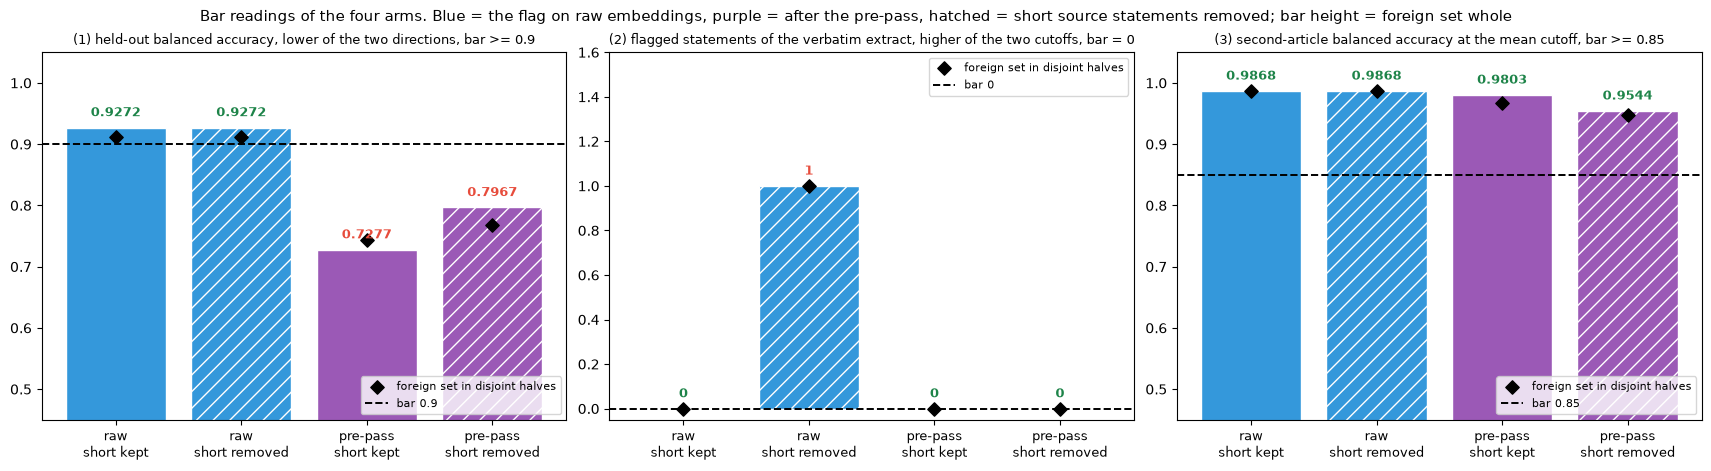

In [19]:
def arm_bars(ax, values: dict, threshold: float, title: str, above: bool) -> None:
    """One bar per arm for the whole reading, a diamond for the disjoint reading; value in green = clause met"""
    xs = np.arange(len(ARMS))
    whole = [values[arm]["whole"] for arm in ARMS]
    ax.bar(xs, whole, color=[ARM_COLOR[a] for a in ARMS], hatch=[ARM_HATCH[a] for a in ARMS], edgecolor="white")
    ax.scatter(xs, [values[arm]["disjoint"] for arm in ARMS], marker="D", s=46, color="black", zorder=3, label="foreign set in disjoint halves")
    ax.axhline(threshold, color="black", ls="--", lw=1.4, label=f"bar {threshold}")
    for x, v in zip(xs, whole):
        ok = v >= threshold if above else v <= threshold
        ax.annotate(f"{v:.4f}" if above else f"{v:.0f}", (x, v), ha="center", va="bottom", fontsize=9, fontweight="bold",
                    color=C_OWN_B if ok else C_FOREIGN, xytext=(0, 6), textcoords="offset points")
    ax.set_xticks(xs); ax.set_xticklabels([ARM_TICK[a] for a in ARMS], fontsize=9)
    ax.set_title(title, fontsize=9); ax.legend(fontsize=8, loc="lower right" if above else "upper right")


fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
arm_bars(axes[0], {a: {fr: BAR[a][fr]["held_ba_min"] for fr in FOREIGN_READINGS} for a in ARMS}, BAR_HELD_BA,
         f"(1) held-out balanced accuracy, lower of the two directions, bar >= {BAR_HELD_BA}", above=True)
arm_bars(axes[1], {a: {fr: max(BAR[a][fr]["extract_flagged"].values()) for fr in FOREIGN_READINGS} for a in ARMS}, BAR_EXTRACT_FLAGGED,
         f"(2) flagged statements of the verbatim extract, higher of the two cutoffs, bar = {BAR_EXTRACT_FLAGGED}", above=False)
arm_bars(axes[2], {a: {fr: BAR[a][fr]["second_ba"] for fr in FOREIGN_READINGS} for a in ARMS}, BAR_SECOND_BA,
         f"(3) second-article balanced accuracy at the mean cutoff, bar >= {BAR_SECOND_BA}", above=True)
axes[0].set_ylim(0.45, 1.05); axes[1].set_ylim(-0.05, 1.6); axes[2].set_ylim(0.45, 1.05)
fig.suptitle("Bar readings of the four arms. Blue = the flag on raw embeddings, purple = after the pre-pass, hatched = short source "
             "statements removed; bar height = foreign set whole", fontsize=11)
plt.show()

**Reading** - the registered row meets the three clauses. Of the eight rows, the two rows on raw embeddings with the short source statements kept meet the bar; the other six do not.

- **Registered row** - held-out balanced accuracy 0.9412 and 0.9272, extract 0 and 0 flagged, second article 0.9868
- **Same arm, foreign set in disjoint halves** - 0.9559 and 0.9125, 0 and 0, 0.9868: met
- **Short source statements removed** - clauses (1) and (3) unchanged, clause (2) not met with 1 and 1 flagged
- **After the pre-pass** - clause (1) is not met in all four rows (0.7277 to 0.8429); clauses (2) and (3) are met
- **What the bar tested** - clause (2) cannot fail on an arm that keeps the short source statements. The own side of clause (3) is close to 1 by construction for the section statements. The readings that could fail are the two held-out readings of clause (1) and the foreign side of clause (3); all three are on the passing side

## Reported without a bar

The readings the record asks for beside the bar: the count under insertions and deletions on the held-out
documents, the shipped residual on the same insertions, the mean cost per tier, and the adversarial summaries
against the per-statement entailment of `E12-H69`.

### Insertion and deletion doses on the held-out documents

Each gold-tier document is scored with the cutoff of the direction in which it is held out. An insertion trial
appends `k` foreign statements and reads how far the count rises; the record asks for the share of trials where
it rises by exactly `k`. A deletion trial removes `k` own statements. On the raw embeddings the cost of a
statement does not depend on the other statements of the document, so deleting statements that are not flagged
cannot change the count: that reading is 0 by construction and is printed as a check of the code, not as a
finding. The mean of the same costs is read on the same doses beside the count.

In [20]:
def count_trials(arm: str, foreign_reading: str) -> dict:
    """Counts and mean costs of every dosed held-out document of one arm"""
    spec = ARMS[arm]
    S = SOURCE[spec["short"]]
    shape = (len(GOLD_TIER), N_SEEDS, len(KS))
    out = {"ins_count": np.zeros((len(GOLD_TIER), N_SEEDS, len(INSERT_KS)), dtype=int),
           "ins_mean": np.zeros((len(GOLD_TIER), N_SEEDS, len(INSERT_KS))),
           "del_any": np.zeros(shape, dtype=int), "del_any_removed_flagged": np.zeros(shape, dtype=int),
           "del_any_mean": np.zeros(shape), "del_supported": np.full(shape, np.nan)}   # NaN = fewer than k statements are not flagged
    for di, label in enumerate(GOLD_TIER):
        cutoff = CAL[arm][foreign_reading]["directions"][HELD_DIRECTION[label]]["cutoff"]
        base = statement_costs(E[label], S, spec["embedding"])
        flagged = base > cutoff
        out["ins_count"][di, :, 0], out["ins_mean"][di, :, 0] = flagged.sum(), base.mean()
        for seed in range(N_SEEDS):
            for ki, k in enumerate(KS, start=1):
                costs = statement_costs(insertion_dose(label, DRAWS[foreign_reading][label][seed], k), S, spec["embedding"])
                out["ins_count"][di, seed, ki], out["ins_mean"][di, seed, ki] = (costs > cutoff).sum(), costs.mean()
            order = DELETE_ORDERS[label][seed]
            supported = order[~flagged[order]]                        # the same order, statements that are not flagged
            for ki, k in enumerate(KS):
                costs = statement_costs(np.delete(E[label], order[:k], axis=0), S, spec["embedding"])
                out["del_any"][di, seed, ki] = (costs > cutoff).sum() - flagged.sum()
                out["del_any_removed_flagged"][di, seed, ki] = flagged[order[:k]].sum()
                out["del_any_mean"][di, seed, ki] = costs.mean() - base.mean()
                if len(supported) >= k:
                    costs = statement_costs(np.delete(E[label], supported[:k], axis=0), S, spec["embedding"])
                    out["del_supported"][di, seed, ki] = (costs > cutoff).sum() - flagged.sum()
    return out


jobs = [(arm, fr) for arm in ARMS for fr in FOREIGN_READINGS]
TRIALS = {}
for arm, fr in tqdm(jobs, desc="count trials (arm, foreign reading)", mininterval=15.0, file=sys.stdout):
    TRIALS[(arm, fr)] = count_trials(arm, fr)
assert all(len(E[label]) - max(KS) >= 1 for label in GOLD_TIER), "every gold-tier document must keep a statement at every deletion dose"

count trials (arm, foreign reading):   0%|          | 0/8 [00:00<?, ?it/s]

count trials (arm, foreign reading): 100%|██████████| 8/8 [00:12<00:00,  1.52s/it]

In [21]:
HELD_ROWS = {name: np.array([HELD_DIRECTION[label] == name for label in GOLD_TIER]) for name in DIRECTIONS}
GOLD_ROWS = [LABELS.index(label) for label in GOLD_TIER]


def trial_reading(trials: dict) -> dict:
    """The record's reported readings of one arm: exact-k share under insertions, count change under deletions"""
    ks = np.array(KS)
    rise = trials["ins_count"][:, :, 1:] - trials["ins_count"][:, :, :1]
    exact = rise == ks
    one_insertion = float((trials["ins_mean"][:, :, 1] - trials["ins_mean"][:, :, 0]).mean())
    median_abs = float(np.median(np.abs(trials["del_any_mean"])))
    supported = trials["del_supported"]
    exists = ~np.isnan(supported)                                   # doses where k statements that are not flagged exist
    return {
        "base_count": {label: int(trials["ins_count"][di, 0, 0]) for di, label in enumerate(GOLD_TIER)},
        "exact_k_share": [float(exact[:, :, ki].mean()) for ki in range(len(KS))],
        "exact_k_share_all_k": float(exact.mean()),
        "exact_k_share_by_direction": {name: float(exact[rows].mean()) for name, rows in HELD_ROWS.items()},
        "rise_below_k_share": float((rise < ks).mean()), "rise_above_k_share": float((rise > ks).mean()),
        "mean_rise": [float(rise[:, :, ki].mean()) for ki in range(len(KS))],
        "n_insertion_trials": int(exact.size),
        "supported_cases": int(exists.sum()),
        "supported_zero_share": float((supported[exists] == 0).mean()) if exists.any() else None,
        "supported_nonzero_cases": int((supported[exists] != 0).sum()),
        "any_zero_share": float((trials["del_any"] == 0).mean()),
        "any_mean_change": float(trials["del_any"].mean()),
        "any_equals_minus_removed_flagged_share": float((trials["del_any"] == -trials["del_any_removed_flagged"]).mean()),
        "n_deletion_cases": int(trials["del_any"].size),
        "mean_cost_median_abs_delta": median_abs, "mean_cost_one_insertion": one_insertion,
        "mean_cost_deletion_ratio": median_abs / one_insertion if one_insertion > 0 else None,
    }


def share_text(value) -> str:
    """A ratio as a percentage; None means the one-insertion effect of that arm is not positive"""
    return "undefined" if value is None else f"{value:.1%}"


TRIAL = {key: trial_reading(trials) for key, trials in TRIALS.items()}
BASELINE_DOSE = {short: {key: {"mean_by_k": [float(v) for v in shipped(short, key)[GOLD_ROWS].mean((0, 1))],
                               "per_document_spearman": {label: float(v) for label, v in
                                                         zip(GOLD_TIER, per_document_spearman(shipped(short, key)[GOLD_ROWS]))},
                               "median_spearman_gold_tier": float(np.median(per_document_spearman(shipped(short, key)[GOLD_ROWS]))),
                               "n_negative_gold_tier": int((per_document_spearman(shipped(short, key)[GOLD_ROWS]) < 0).sum()),
                               "median_spearman_11_documents": float(np.median(per_document_spearman(shipped(short, key))))}
                         for key in SHIPPED_KEYS} for short in SOURCE}

it = Table(title=f"Insertion doses - {len(GOLD_TIER)} held-out documents x {N_SEEDS} seeds x k in {KS} "
                 f"({TRIAL[(VERDICT_ARM, 'whole')]['n_insertion_trials']} trials per row): share of trials where the count rises by exactly k",
           header_style="bold cyan")
for col in ("arm", "foreign reading", *[f"k = {k}" for k in KS], "all k", "held out in A→B / B→A", "rise below k", "rise above k",
            "mean rise at k = 1, 2, 3, 4"):
    it.add_column(col, justify="left" if col in ("arm", "foreign reading") else "right")
dt = Table(title=f"Deletion doses - {len(GOLD_TIER)} held-out documents x {N_SEEDS} seeds x k in {KS} "
                 f"({TRIAL[(VERDICT_ARM, 'whole')]['n_deletion_cases']} cases per row): change of the count, and of the mean cost on the same doses",
           header_style="bold cyan")
for col in ("arm", "foreign reading", "supported statements deleted: cases", "supported: count unchanged", "any statement deleted: count unchanged",
            "any: mean change of the count", "any: change = -(deleted flagged statements)", "mean cost: median |change|",
            "mean cost: one insertion", "mean cost: ratio"):
    dt.add_column(col, justify="left" if col in ("arm", "foreign reading") else "right")
for (arm, fr), r in TRIAL.items():
    style = "bold" if (arm, fr) == (VERDICT_ARM, VERDICT_FOREIGN) else None
    it.add_row(ARMS[arm]["label"], FOREIGN_READINGS[fr], *[f"{v:.4f}" for v in r["exact_k_share"]], f"{r['exact_k_share_all_k']:.4f}",
               " / ".join(f"{r['exact_k_share_by_direction'][name]:.4f}" for name in DIRECTIONS), f"{r['rise_below_k_share']:.4f}",
               f"{r['rise_above_k_share']:.4f}", "  ".join(f"{v:.3f}" for v in r["mean_rise"]), style=style)
    dt.add_row(ARMS[arm]["label"], FOREIGN_READINGS[fr], str(r["supported_cases"]),
               "no case" if r["supported_zero_share"] is None else f"{r['supported_zero_share']:.4f}", f"{r['any_zero_share']:.4f}",
               f"{r['any_mean_change']:+.4f}", f"{r['any_equals_minus_removed_flagged_share']:.4f}", f"{r['mean_cost_median_abs_delta']:.5f}",
               f"{r['mean_cost_one_insertion']:+.5f}", share_text(r["mean_cost_deletion_ratio"]), style=style)

pt = Table(title="Count of each gold-tier document at k = 0 under the cutoff of the direction in which it is held out", header_style="bold cyan")
pt.add_column("document"); pt.add_column("half"); pt.add_column("held out in"); pt.add_column("statements", justify="right")
for arm in ARMS:
    pt.add_column(f"{ARMS[arm]['label']}: whole / disjoint", justify="right")
for label in GOLD_TIER:
    pt.add_row(label, HALF_OF[label], HELD_DIRECTION[label], str(len(E[label])),
               *[f"{TRIAL[(arm, 'whole')]['base_count'][label]} / {TRIAL[(arm, 'disjoint')]['base_count'][label]}" for arm in ARMS])

st = Table(title=f"Baseline on the same insertion doses (the E13-H73 draws), {len(GOLD_TIER)} gold-tier documents", header_style="bold cyan")
for col in ("source", "reading", "mean at k = 0, 1, 2, 3, 4", "median per-document Spearman, 7 gold-tier documents",
            "documents with a negative Spearman, of 7", "median per-document Spearman, 11 documents"):
    st.add_column(col, justify="left" if col in ("source", "reading") else "right")
for short in SOURCE:
    for key in SHIPPED_KEYS:
        b = BASELINE_DOSE[short][key]
        st.add_row(f"short {short}", SHIPPED_LABEL[key], "  ".join(f"{v:.4f}" for v in b["mean_by_k"]),
                   f"{b['median_spearman_gold_tier']:+.4f}", str(b["n_negative_gold_tier"]), f"{b['median_spearman_11_documents']:+.4f}")
console.print(Group(it, pt, dt, st))

                   Insertion doses - 7 held-out documents x 14 seeds x k in (1, 2, 3, 4) (392 trials per row): share of trials where the count rises by exactly k                   
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                          ┃                         ┃        ┃        ┃        ┃        ┃        ┃                       ┃              ┃              ┃   mean rise at k = 1, 2, ┃
┃ arm                      ┃ foreign reading         ┃  k = 1 ┃  k = 2 ┃  k = 3 ┃  k = 4 ┃  all k ┃ held out in A→B / B→A ┃ rise below k ┃ rise above k ┃                     3, 4 ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ raw, short kept          │ foreign set whole       │ 0.9490 │ 0.9286 │ 0.8980 │ 0.8673 │ 0.9107 │       1.0000 / 0.8438 │       0.0893 │       0.0000 │      0.949  1.929  2.898 │
│ (registered)             │ (registered)            │        │        │        │        │        │                       │              │              │                    3.867 │
│ raw, short kept          │ foreign set in disjoint │ 0.9082 │ 0.8673 │ 0.8469 │ 0.8061 │ 0.8571 │       1.0000 / 0.7500 │       0.1429 │       0.0000 │      0.908  1.867  2.837 │
│ (registered)             │ halves                  │        │        │        │        │        │                       │              │              │                    3.796 │
│ raw, short removed       │ foreign set whole       │ 0.9490 │ 0.9286 │ 0.8980 │ 0.8673 │ 0.9107 │       1.0000 / 0.8438 │       0.0893 │       0.0000 │      0.949  1.929  2.898 │
│                          │ (registered)            │        │        │        │        │        │                       │              │              │                    3.867 │
│ raw, short removed       │ foreign set in disjoint │ 0.9082 │ 0.8673 │ 0.8469 │ 0.8061 │ 0.8571 │       1.0000 / 0.7500 │       0.1429 │       0.0000 │      0.908  1.867  2.837 │
│                          │ halves                  │        │        │        │        │        │                       │              │              │                    3.796 │
│ pre-pass, short kept     │ foreign set whole       │ 0.6837 │ 0.5816 │ 0.4082 │ 0.3265 │ 0.5000 │       0.6012 / 0.4241 │       0.4056 │       0.0944 │      0.898  1.633  2.265 │
│                          │ (registered)            │        │        │        │        │        │                       │              │              │                    3.092 │
│ pre-pass, short kept     │ foreign set in disjoint │ 0.7347 │ 0.6122 │ 0.4898 │ 0.4898 │ 0.5816 │       0.7976 / 0.4196 │       0.3750 │       0.0434 │      0.724  1.510  2.520 │
│                          │ halves                  │        │        │        │        │        │                       │              │              │                    3.541 │
│ pre-pass, short removed  │ foreign set whole       │ 0.7347 │ 0.6122 │ 0.4490 │ 0.3878 │ 0.5459 │       0.2917 / 0.7366 │       0.4541 │       0.0000 │      0.694  1.520  2.296 │
│                          │ (registered)            │        │        │        │        │        │                       │              │              │                    3.173 │
│ pre-pass, short removed  │ foreign set in disjoint │ 0.8061 │ 0.4694 │ 0.3061 │ 0.1429 │ 0.4311 │       0.4762 / 0.3973 │       0.5689 │       0.0000 │      0.786  1.347  2.000 │
│                          │ halves                  │        │        │        │        │        │                       │              │              │                    2.765 │
└──────────────────────────┴─────────────────────────┴────────┴────────┴────────┴────────┴────────┴───────────────────────┴──────────────┴──────────────┴──────────────────────────┘
                  

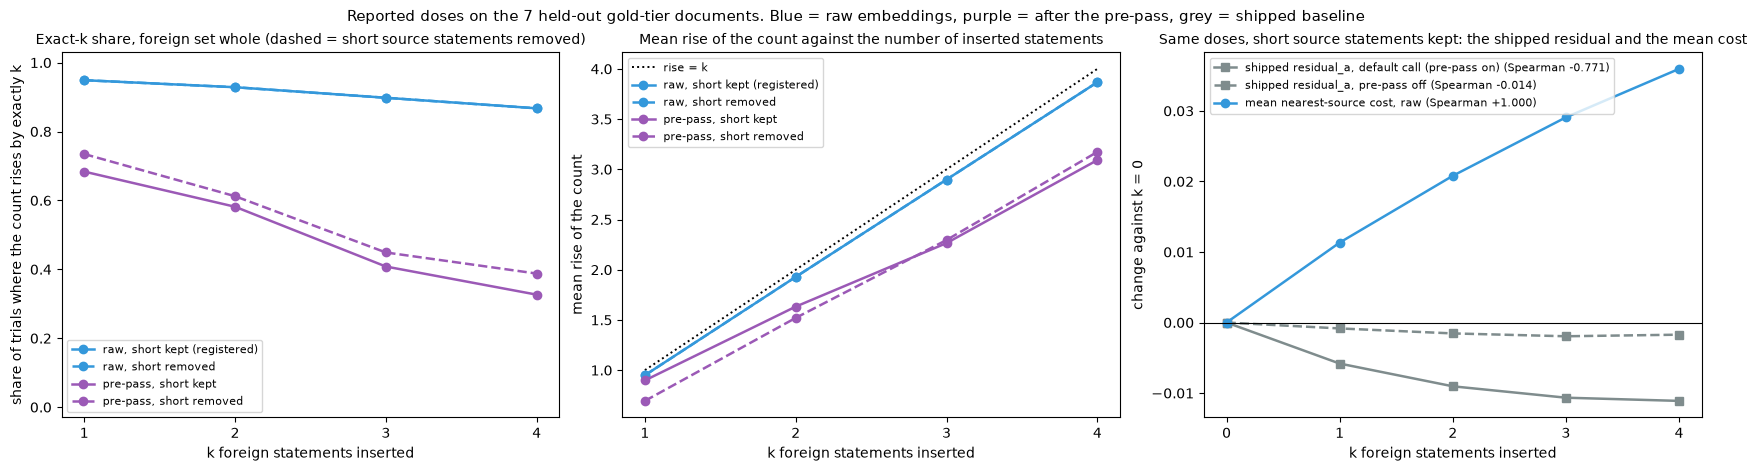

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
ax = axes[0]
for arm in ARMS:
    ax.plot(KS, TRIAL[(arm, "whole")]["exact_k_share"], color=ARM_COLOR[arm], ls="--" if ARM_HATCH[arm] else "-", marker="o", lw=1.8,
            label=ARMS[arm]["label"])
ax.set_ylim(-0.03, 1.03); ax.set_xticks(KS)
ax.set_xlabel("k foreign statements inserted"); ax.set_ylabel("share of trials where the count rises by exactly k")
ax.set_title("Exact-k share, foreign set whole (dashed = short source statements removed)", fontsize=10); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(KS, KS, color="black", ls=":", lw=1.4, label="rise = k")
for arm in ARMS:
    ax.plot(KS, TRIAL[(arm, "whole")]["mean_rise"], color=ARM_COLOR[arm], ls="--" if ARM_HATCH[arm] else "-", marker="o", lw=1.8,
            label=ARMS[arm]["label"])
ax.set_xticks(KS); ax.set_xlabel("k foreign statements inserted"); ax.set_ylabel("mean rise of the count")
ax.set_title("Mean rise of the count against the number of inserted statements", fontsize=10); ax.legend(fontsize=8)

ax = axes[2]
series = (("bal_pre", C_BASELINE, "-", "s"), ("bal_raw", C_BASELINE, "--", "s"), ("os_raw", C_LEVER, "-", "o"))
for key, colour, ls, marker in series:
    by_k = np.array(BASELINE_DOSE["kept"][key]["mean_by_k"])
    ax.plot(INSERT_KS, by_k - by_k[0], color=colour, ls=ls, marker=marker, lw=1.8,
            label=f"{SHIPPED_LABEL[key]} (Spearman {BASELINE_DOSE['kept'][key]['median_spearman_gold_tier']:+.3f})")
ax.axhline(0, color="black", lw=0.8); ax.set_xticks(INSERT_KS)
ax.set_xlabel("k foreign statements inserted"); ax.set_ylabel("change against k = 0")
ax.set_title("Same doses, short source statements kept: the shipped residual and the mean cost", fontsize=10); ax.legend(fontsize=8)
fig.suptitle("Reported doses on the 7 held-out gold-tier documents. Blue = raw embeddings, purple = after the pre-pass, grey = shipped baseline",
             fontsize=11)
plt.show()

**Reading** - on the registered arm the count rises by exactly the number of inserted foreign statements in 91.07% of the 392 trials, and it does not change when statements that are not flagged are deleted. On the default call the shipped residual falls under the same insertions.

- **Exact-k share** - 0.9490, 0.9286, 0.8980 and 0.8673 for `k` = 1 to 4. A trial misses when an inserted statement lies below the cutoff: the rise is below `k` in 8.93% of the trials and never above `k`
- **By direction** - 1.0000 for the documents scored with the cutoff 0.3375, which all 38 foreign statements exceed, and 0.8438 for the documents scored with 0.3550, which 36 of the 38 exceed
- **Disjoint reading** - 0.9082, 0.8673, 0.8469 and 0.8061; 0.8571 over all `k`
- **Count of the faithful summaries themselves** - at `k` = 0 the 7 gold-tier documents read 0, 1, 1, 1, 2, 0 and 3 flagged statements under their held-out cutoff. 5 of the 7 documents read a count above 0
- **Deletions of supported statements** - the count is unchanged in 392 of 392 cases. On raw embeddings this is 0 by construction; the reading confirms the code and is not a finding
- **Deletions of any statement** - the count is unchanged in 75.51% of the cases and falls by 0.2704 on average. Every change equals minus the number of deleted flagged statements, so the count falls only when a flagged statement is deleted
- **The mean on the same doses** - the mean nearest-source cost moves by a median of 0.00516 under these deletions, 45.6% of its one-insertion effect of 0.01133. This is the response that failed `E13-H73`, which read 34.1% over the 11 summaries
- **After the pre-pass** - exact-k share 0.6837 falling to 0.3265, a rise above `k` in 9.44% of the trials, and an unchanged count in 81.89% of the supported-statement deletions. Inside the pre-pass every cost depends on the pooled statements, so the count is not invariant there
- **Shipped residual, default call** - 1.2318 → 1.2207 over `k` = 0 to 4, median per-document Spearman -0.7714, negative on 7 of 7 documents
- **Shipped residual, pre-pass off** - 0.7026 → 0.7009, median per-document Spearman -0.0143, negative on 4 of 7 documents. On the 7 gold-tier documents this response is close to zero; the -0.2571 of `E13-H73` is the median over 11 documents
- **Short source statements removed** - the shipped residual with the pre-pass off rises instead: 0.3931 → 0.3998, Spearman +0.5929, negative on 0 of 7 documents

### Mean cost per tier and the adversarial summaries against entailment

The mean nearest-source cost of each summary and of each tier: gold (7 faithful summaries), adv1 (2 summaries with
information loss) and adv2 (2 summaries with information noise). The count is read with the mean cutoff of the
arm; each gold-tier document took part in the calibration of one of the two cutoffs, so its count here is not a
held-out reading. The statements of the 4 adversarial summaries are then compared with the per-statement
entailment that `E12-H69` stored: does a statement that the NLI model reads as not entailed lie further from its
nearest source statement.

In [23]:
signals = np.load(GROUNDING_NPZ)
NOT_ENTAILED = {label: 1.0 - signals[f"ent__{label}"].astype(float) for label in LABELS}
DOC_COSTS = {arm: {label: statement_costs(E[label], SOURCE[spec["short"]], spec["embedding"]) for label in LABELS}
             for arm, spec in ARMS.items()}


def tier_reading(arm: str) -> dict:
    """Mean cost and count per document and per tier under the mean cutoff of the arm (foreign set whole)"""
    cutoff = CAL[arm]["whole"]["mean_cutoff"]
    mean_cost = {label: float(DOC_COSTS[arm][label].mean()) for label in LABELS}
    count = {label: int((DOC_COSTS[arm][label] > cutoff).sum()) for label in LABELS}
    members = {tier: [l for l in LABELS if TIER[l] == tier] for tier in TIERS}
    return {"cutoff": cutoff, "mean_cost": mean_cost, "count": count,
            "tier_mean_cost": {tier: float(np.mean([mean_cost[l] for l in members[tier]])) for tier in TIERS},
            "tier_count": {tier: int(sum(count[l] for l in members[tier])) for tier in TIERS},
            "tier_statements": {tier: int(sum(len(E[l]) for l in members[tier])) for tier in TIERS}}


def entailment_agreement(arm: str, labels: list) -> dict:
    """Nearest-source cost against 1 - entailment over the statements of the given summaries"""
    cost = np.concatenate([DOC_COSTS[arm][label] for label in labels])
    u = np.concatenate([NOT_ENTAILED[label] for label in labels])
    positive = u > ENTAIL_LABEL_MIN
    higher = (u[:, None] - u[None, :]) > 0                          # every pair with different entailment, once
    dc = cost[:, None] - cost[None, :]
    flagged = cost > CAL[arm]["whole"]["mean_cutoff"]
    return {
        "n": int(cost.size), "n_not_entailed": int(positive.sum()),
        "auc_binary": auc_of(cost[~positive], cost[positive]) if positive.any() and (~positive).any() else None,
        "concordance": float(((dc[higher] > 0).sum() + 0.5 * (dc[higher] == 0).sum()) / higher.sum()),
        "spearman": float(spearmanr(cost, u).statistic),
        "flagged": int(flagged.sum()), "flagged_and_not_entailed": int((flagged & positive).sum()),
        "not_flagged_and_not_entailed": int((~flagged & positive).sum()),
    }


TIERS_READ = {arm: tier_reading(arm) for arm in ARMS}
ENTAIL = {arm: {"adversarial": entailment_agreement(arm, ADV), "all_summaries": entailment_agreement(arm, LABELS)} for arm in ARMS}

tt = Table(title="Mean nearest-source cost and count per summary, count under the mean cutoff of the arm (foreign set whole)", header_style="bold cyan")
tt.add_column("document"); tt.add_column("tier"); tt.add_column("statements", justify="right")
for arm in ARMS:
    tt.add_column(f"{ARMS[arm]['label']}: mean cost / count", justify="right")
for label in LABELS:
    tt.add_row(label, TIER[label], str(len(E[label])),
               *[f"{TIERS_READ[arm]['mean_cost'][label]:.4f} / {TIERS_READ[arm]['count'][label]}" for arm in ARMS], style=TIER_COLOR[TIER[label]])
for tier in TIERS:
    tt.add_row(f"mean, {tier} tier", tier, str(TIERS_READ[VERDICT_ARM]["tier_statements"][tier]),
               *[f"{TIERS_READ[arm]['tier_mean_cost'][tier]:.4f} / {TIERS_READ[arm]['tier_count'][tier]}" for arm in ARMS], style="bold")
tt.add_row("mean cutoff of the arm", "-", "-", *[f"{TIERS_READ[arm]['cutoff']:.5f}" for arm in ARMS])

at = Table(title=f"Nearest-source cost against 1 - entailment (E12-H69 signals); not entailed = 1 - entailment > {ENTAIL_LABEL_MIN}",
           header_style="bold cyan")
for col in ("arm", "statements", "n", "not entailed", "AUC (cost, not entailed against entailed)", "concordance, all pairs", "Spearman",
            "flagged", "flagged and not entailed", "not flagged and not entailed"):
    at.add_column(col, justify="left" if col in ("arm", "statements") else "right")
for arm in ARMS:
    for name, title in (("adversarial", "4 adversarial summaries (record)"), ("all_summaries", "all 11 summaries")):
        r = ENTAIL[arm][name]
        at.add_row(ARMS[arm]["label"], title, str(r["n"]), str(r["n_not_entailed"]),
                   "undefined" if r["auc_binary"] is None else f"{r['auc_binary']:.4f}", f"{r['concordance']:.4f}", f"{r['spearman']:+.4f}",
                   str(r["flagged"]), str(r["flagged_and_not_entailed"]), str(r["not_flagged_and_not_entailed"]),
                   style="bold" if arm == VERDICT_ARM and name == "adversarial" else None)
console.print(Group(tt, at))

                                     Mean nearest-source cost and count per summary, count under the mean cutoff of the arm (foreign set whole)                                     
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                        ┃      ┃            ┃   raw, short kept (registered): ┃  raw, short removed: mean cost ┃ pre-pass, short kept: mean cost ┃  pre-pass, short removed: mean ┃
┃ document               ┃ tier ┃ statements ┃               mean cost / count ┃                        / count ┃                         / count ┃                   cost / count ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold                   │ gold │         10 │                      0.2858 / 1 │                     0.2858 / 1 │                      0.9949 / 4 │                     1.0604 / 4 │
│ gold-2                 │ gold │         12 │                      0.2571 / 0 │                     0.2571 / 0 │                      0.9097 / 1 │                     0.9764 / 3 │
│ v1                     │ gold │         11 │                      0.2789 / 1 │                     0.2789 / 1 │                      0.9363 / 2 │                     1.0713 / 3 │
│ v2                     │ gold │         11 │                      0.2853 / 1 │                     0.2853 / 1 │                      1.0062 / 2 │                     1.0818 / 4 │
│ opus                   │ gold │         11 │                      0.3059 / 2 │                     0.3059 / 2 │                      1.0258 / 3 │                     1.0758 / 4 │
│ sonnet                 │ gold │          9 │                      0.2663 / 0 │                     0.2663 / 0 │                      0.9560 / 3 │                     1.0001 / 2 │
│ haiku                  │ gold │         13 │                      0.3009 / 3 │                     0.3009 / 3 │                      1.0275 / 5 │                     1.1182 / 5 │
│ adv1-a                 │ adv1 │          8 │                      0.3603 / 4 │                     0.3603 / 4 │                      1.2157 / 7 │                     1.2233 / 7 │
│ adv1-b                 │ adv1 │          9 │                      0.3519 / 5 │                     0.3519 / 5 │                      1.2166 / 9 │                     1.1847 / 7 │
│ adv2-a                 │ adv2 │          1 │                      0.3162 / 0 │                     0.3162 / 0 │                      1.2612 / 1 │                     1.1440 / 1 │
│ adv2-b                 │ adv2 │          3 │                      0.3208 / 0 │                     0.3208 / 0 │                      1.1094 / 2 │                     1.1944 / 3 │
│ mean, gold tier        │ gold │         77 │                      0.2829 / 8 │                     0.2829 / 8 │                     0.9795 / 20 │                    1.0549 / 25 │
│ mean, adv1 tier        │ adv1 │         17 │                      0.3561 / 9 │                     0.3561 / 9 │                     1.2161 / 16 │                    1.2040 / 14 │
│ mean, adv2 tier        │ adv2 │          4 │                      0.3185 / 0 │                     0.3185 / 0 │                      1.1853 / 3 │                     1.1692 / 4 │
│ mean cutoff of the arm │ -    │          - │                         0.34625 │                        0.34625 │                         1.11500 │                        1.14000 │
└────────────────────────┴──────┴────────────┴─────────────────────────────────┴────────────────────────────────┴─────────────────────────────────┴────────────────────────────────┘
                                         Nearest-source cost against 1 - entailment (E12-H69 signals); not entailed = 1 - entailment > 0.5                                          
┏━━━━━━━━━━━━━━━━━

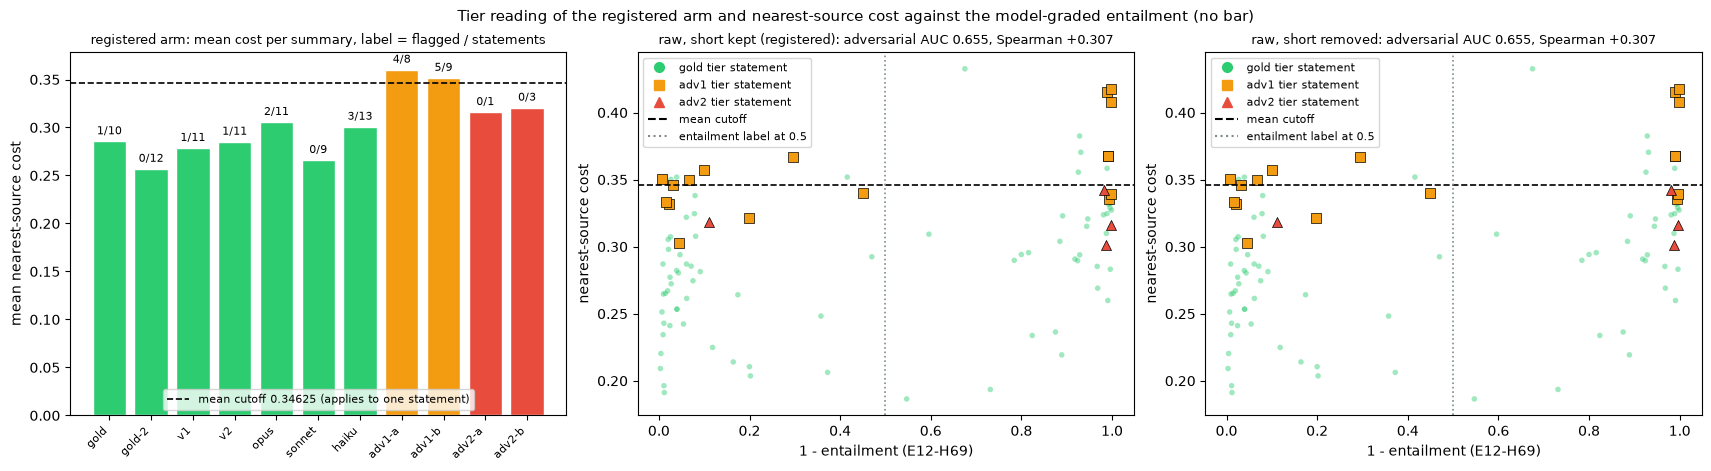

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
ax = axes[0]
xs = np.arange(len(LABELS))
tr = TIERS_READ[VERDICT_ARM]
ax.bar(xs, [tr["mean_cost"][l] for l in LABELS], color=[TIER_COLOR[TIER[l]] for l in LABELS], edgecolor="white")
for x, label in zip(xs, LABELS):
    ax.annotate(f"{tr['count'][label]}/{len(E[label])}", (x, tr["mean_cost"][label]), ha="center", va="bottom", fontsize=8,
                xytext=(0, 3), textcoords="offset points")
ax.axhline(tr["cutoff"], color="black", ls="--", lw=1.2, label=f"mean cutoff {tr['cutoff']:.5f} (applies to one statement)")
ax.set_xticks(xs); ax.set_xticklabels(LABELS, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("mean nearest-source cost"); ax.legend(fontsize=8, loc="lower center")
ax.set_title("registered arm: mean cost per summary, label = flagged / statements", fontsize=9)

marker_of = {"gold": "o", "adv1": "s", "adv2": "^"}
for ax, arm in zip(axes[1:], RAW_ARMS):
    for label in LABELS:
        adversarial = TIER[label] != "gold"
        ax.scatter(NOT_ENTAILED[label], DOC_COSTS[arm][label], color=TIER_COLOR[TIER[label]], marker=marker_of[TIER[label]],
                   s=52 if adversarial else 16, alpha=1.0 if adversarial else 0.45, edgecolor="black" if adversarial else "none", linewidth=0.5)
    ax.axhline(TIERS_READ[arm]["cutoff"], color="black", ls="--", lw=1.2)
    ax.axvline(ENTAIL_LABEL_MIN, color=C_BASELINE, ls=":", lw=1.2)
    r = ENTAIL[arm]["adversarial"]
    auc_text = "undefined" if r["auc_binary"] is None else f"{r['auc_binary']:.3f}"
    ax.set_title(f"{ARMS[arm]['label']}: adversarial AUC {auc_text}, Spearman {r['spearman']:+.3f}", fontsize=9)
    ax.set_xlabel("1 - entailment (E12-H69)"); ax.set_ylabel("nearest-source cost")
    handles = [plt.Line2D([], [], color=TIER_COLOR[t], marker=marker_of[t], ls="", ms=7, label=f"{t} tier statement") for t in TIERS]
    handles.append(plt.Line2D([], [], color="black", ls="--", label="mean cutoff"))
    handles.append(plt.Line2D([], [], color=C_BASELINE, ls=":", label=f"entailment label at {ENTAIL_LABEL_MIN}"))
    ax.legend(handles=handles, fontsize=8)
fig.suptitle("Tier reading of the registered arm and nearest-source cost against the model-graded entailment (no bar)", fontsize=11)
plt.show()

**Reading** - no bar applies. The count is higher on the information-loss summaries than on the faithful ones and reads 0 on the information-noise summaries. Against the model-graded entailment the cost is a weak signal.

- **Mean cost per tier, registered arm** - gold 0.2829, adv1 0.3561, adv2 0.3185, the `E13-H73` values
- **Count at the mean cutoff 0.34625** - gold tier 8 of 77 statements, adv1 9 of 17 (4 of 8 and 5 of 9), adv2 0 of 4. No adv2 statement is flagged, while both adv2 documents have a mean cost above every gold-tier document (0.3162 and 0.3208 against at most 0.3059)
- **The gold-tier counts here are not held-out** - each gold-tier document took part in the calibration of one of the two cutoffs
- **Against entailment, 21 adversarial statements** - 10 are labelled not entailed. AUC of the cost 0.6545, concordance over all pairs 0.6077, Spearman +0.3073. The flag marks 9 statements; of the 10 statements labelled not entailed, 5 are flagged and 5 are not
- **Against entailment, all 98 statements** - 43 are labelled not entailed. AUC 0.6778, Spearman +0.4074; 33 of the 43 are not flagged
- **Short source statements removed** - identical. **After the pre-pass, short kept** - AUC 0.6909 on the adversarial statements and 0.6021 on all statements
- **Meaning** - the flag reads the distance of a statement to the source article. A statement on the topic of the article that the source does not support lies close to source statements and is not flagged. The count is not a replacement for the model-graded grounding residual

## Guardrails, measured

The standing guardrails of stage A, each one measured:

- **V** - ordinality violations of the naive panel (shipped `smd` against the anchor), counted before and after the arms
- **Default-path bit identity** - `smd`, `order_gap` and the three saved source-conditioned results, compared by `np.array_equal` before against after and against the saved 1.1.5 baseline
- **Harness setting** - shipped readings on one BLAS thread against the default thread count, by `np.array_equal`
- **Metric property** - the count is a score; the mean nearest-source cost is a lower bound of the shipped balanced residual, and violations of that bound are counted on every scored document
- **No edit** - per-file byte digests of `src/`, `tests/` and `docs/` before against after, and `git status` on `src/` and `tests/`. The campaign orchestrator writes the ledger under `docs/` while executors run, so the `docs/` row is a reading and not part of the hold condition

In [25]:
check_docs = [E[label] for label in LABELS] + [X_V]
limited = {
    "bal_pre": np.array([shipped("kept", "bal_pre")[di, 0, 0] for di in range(len(LABELS))] + [EXTRACT_SHIPPED["kept"]["on"].residual_a]),
    "pre_costs": np.concatenate([DOC_COSTS["pre_kept"][label] for label in LABELS] + [EXTRACT_COSTS["pre_kept"]]),
}
BLAS_LIMIT.restore_original_limits()        # default BLAS thread count for every reading below

SNAP_AFTER = default_path_snapshot()
PANEL_AFTER = panel_metrics(SNAP_AFTER["smd"])
identical_before_after = {key: bool(np.array_equal(SNAP_BEFORE[key], SNAP_AFTER[key])) for key in SNAP_BEFORE}
saved_equal_after = {key: bool(np.array_equal(SNAP_AFTER[key], SAVED[key])) for key in SAVED}

default_threads = {
    "bal_pre": np.array([compute_source_conditioned(X, X, E_S).residual_a for X in check_docs]),
    "pre_costs": np.concatenate([statement_costs(X, E_S, "pre") for X in check_docs]),
}
thread_identical = {key: bool(np.array_equal(limited[key], default_threads[key])) for key in limited}

# distinct scored documents of the baseline loop: per source reading, 11 summaries and 11 x 14 x 4 dosed documents
n_scored = len(SOURCE) * len(LABELS) * (1 + N_SEEDS * len(KS))
bound_violations = 0
for short in SOURCE:
    for one_sided, balanced in (("os_raw", "bal_raw"), ("os_pre", "bal_pre")):
        over = shipped(short, one_sided) > shipped(short, balanced)
        bound_violations += int(over[:, :, 1:].sum() + over[:, 0, 0].sum())
counts_in_range = all(0 <= int(t["ins_count"].min()) and bool((t["ins_count"] <= np.array([len(E[l]) for l in GOLD_TIER])[:, None, None]
                                                               + np.array(INSERT_KS)[None, None, :]).all()) for t in TRIALS.values())

DIGEST_AFTER = {folder: file_digests(folder) for folder in DIGEST_BEFORE}
files_changed = {folder: sorted(path for path in DIGEST_BEFORE[folder].keys() | DIGEST_AFTER[folder].keys()
                                if DIGEST_BEFORE[folder].get(path) != DIGEST_AFTER[folder].get(path))
                 for folder in DIGEST_BEFORE}
git_src_tests = subprocess.run(["git", "status", "--porcelain", "--", "src", "tests"], cwd=ROOT,
                               capture_output=True, text=True).stdout.strip()
src_untouched = not files_changed["src"] and not files_changed["tests"] and git_src_tests == ""

GUARD = {
    "V before the arms": (f"{PANEL_BEFORE['V']}/24", PANEL_BEFORE["V"] == 0),
    "V after the arms": (f"{PANEL_AFTER['V']}/24", PANEL_AFTER["V"] == 0),
    "smd, 10 anchor pairs, before == after (np.array_equal)": (str(identical_before_after["smd"]), identical_before_after["smd"]),
    "order_gap, 10 anchor pairs, before == after (np.array_equal)": (str(identical_before_after["order_gap"]), identical_before_after["order_gap"]),
    "source-conditioned, 3 saved pairs x 5 fields, before == after (np.array_equal)": (
        str(identical_before_after["source_conditioned"]), identical_before_after["source_conditioned"]),
    "smd == saved 1.1.5 baseline (np.array_equal), before / after": (f"{saved_equal_before['smd']} / {saved_equal_after['smd']}",
                                                                     saved_equal_before["smd"] and saved_equal_after["smd"]),
    "order_gap == saved 1.1.5 baseline (np.array_equal), before / after": (
        f"{saved_equal_before['order_gap']} / {saved_equal_after['order_gap']}", saved_equal_before["order_gap"] and saved_equal_after["order_gap"]),
    "source-conditioned == saved 1.1.5 baseline (np.array_equal), before / after": (
        f"{saved_equal_before['source_conditioned']} / {saved_equal_after['source_conditioned']}",
        saved_equal_before["source_conditioned"] and saved_equal_after["source_conditioned"]),
    "mean nearest-source cost > shipped balanced residual (lower-bound violations), scored documents": (
        f"{bound_violations}/{n_scored * 2}", bound_violations == 0),
    "count between 0 and the number of statements, every dosed document": (str(counts_in_range), counts_in_range),
    "src/ files whose bytes changed during the run": (f"{len(files_changed['src'])}/{len(DIGEST_BEFORE['src'])}", not files_changed["src"]),
    "tests/ files whose bytes changed during the run": (f"{len(files_changed['tests'])}/{len(DIGEST_BEFORE['tests'])}", not files_changed["tests"]),
    "git status --porcelain -- src tests is empty": (str(git_src_tests == ""), git_src_tests == ""),
}
guardrails_hold = all(ok for _, ok in GUARD.values())

gr = Table(title="Guardrails - measured", header_style="bold cyan")
gr.add_column("guardrail"); gr.add_column("reading", justify="right"); gr.add_column("verdict")
for name, (value, ok) in GUARD.items():
    gr.add_row(name, value, "[green]holds[/green]" if ok else "[red]BREACH[/red]")
gr.add_row("docs/ files whose bytes changed during the run (other campaign processes write docs/)",
           f"{len(files_changed['docs'])}/{len(DIGEST_BEFORE['docs'])}", "reported")
gr.add_row("1 BLAS thread == default threads, shipped residual_a, 12 documents (np.array_equal)", str(thread_identical["bal_pre"]), "reported")
gr.add_row("1 BLAS thread == default threads, pre-pass statement costs, 12 documents (np.array_equal)", str(thread_identical["pre_costs"]), "reported")
panel_line = (f"naive panel after the arms: V {PANEL_AFTER['V']}/24, margin {PANEL_AFTER['margin_pts']:+.2f} pts, d' {PANEL_AFTER['dprime']:.2f}, "
              f"R {PANEL_AFTER['R']:.3f}, DR {PANEL_AFTER['DR']:.4f}")
docs_line = (f"docs/ files changed during the run: {files_changed['docs'] or 'none'}; "
             f"this notebook writes one file, {REPORT.relative_to(ROOT)}")
console.print(Group(gr, panel_line, docs_line,
                    f"[bold {'green' if guardrails_hold else 'red'}]GUARDRAILS: {'ALL HOLD' if guardrails_hold else 'BREACH'}[/]"))

                                                   Guardrails - measured                                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ guardrail                                                                                       ┃     reading ┃ verdict  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ V before the arms                                                                               │        0/24 │ holds    │
│ V after the arms                                                                                │        0/24 │ holds    │
│ smd, 10 anchor pairs, before == after (np.array_equal)                                          │        True │ holds    │
│ order_gap, 10 anchor pairs, before == after (np.array_equal)                                    │        True │ holds    │
│ source-conditioned, 3 saved pairs x 5 fields, before == after (np.array_equal)                  │        True │ holds    │
│ smd == saved 1.1.5 baseline (np.array_equal), before / after                                    │ True / True │ holds    │
│ order_gap == saved 1.1.5 baseline (np.array_equal), before / after                              │ True / True │ holds    │
│ source-conditioned == saved 1.1.5 baseline (np.array_equal), before / after                     │ True / True │ holds    │
│ mean nearest-source cost > shipped balanced residual (lower-bound violations), scored documents │      0/2508 │ holds    │
│ count between 0 and the number of statements, every dosed document                              │        True │ holds    │
│ src/ files whose bytes changed during the run                                                   │        0/15 │ holds    │
│ tests/ files whose bytes changed during the run                                                 │         0/9 │ holds    │
│ git status --porcelain -- src tests is empty                                                    │        True │ holds    │
│ docs/ files whose bytes changed during the run (other campaign processes write docs/)           │        0/45 │ reported │
│ 1 BLAS thread == default threads, shipped residual_a, 12 documents (np.array_equal)             │        True │ reported │
│ 1 BLAS thread == default threads, pre-pass statement costs, 12 documents (np.array_equal)       │        True │ reported │
└─────────────────────────────────────────────────────────────────────────────────────────────────┴─────────────┴──────────┘
naive panel after the arms: V 0/24, margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873
docs/ files changed during the run: none; this notebook writes one file, reports/E15-H78-raw-nearest-source-count-metrics.json
GUARDRAILS: ALL HOLD

**Reading** - every guardrail holds.

- **V** - 0/24 before and after the arms; the naive panel reads margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873, equal to the primer row
- **Default path** - `smd`, `order_gap` and the three source-conditioned results are bit-identical before and after the arms and equal to the saved 1.1.5 baseline
- **Metric property** - the count is an integer between 0 and the number of statements on every dosed document. The mean nearest-source cost reads above the shipped balanced residual of the same pre-pass setting in 0 of 2508 comparisons
- **No edit** - no file under `src/` or `tests/` changed during the run and both folders are clean in git. This notebook writes one file, the metrics JSON under `reports/`. The `docs/` row counts files that another campaign process wrote during the run and the line under the table names them
- **Harness setting** - one BLAS thread and the default thread count give identical readings on the 12 checked documents

## Verdict against the registered bar

The verdict is read on the arm `raw, short kept` with the foreign set whole, the reading fixed in the
configuration. The order of the checks is the stage A order: kill-gate, harness check, guardrails, then the
acceptance bar. The prediction is checked per effect: **magnitude** is the registered interval, **direction**
follows the configuration rule. The second readings are printed beside the verdict reading.

In [26]:
b = BAR[VERDICT_ARM][VERDICT_FOREIGN]
cal = CAL[VERDICT_ARM][VERDICT_FOREIGN]
second = SECOND[VERDICT_ARM][REGISTERED_SECOND][VERDICT_FOREIGN]
bar_met = bool(b["met"])
null_effect = all(v <= NO_INFORMATION_BA for v in b["held_ba"].values())

if gate_killed:
    VERDICT = "Killed-at-gate"
elif not sanity_ok or not guardrails_hold:
    VERDICT = "Blocked"
elif bar_met:
    VERDICT = "Promoted"
elif null_effect:
    VERDICT = "Refuted (null)"
else:
    VERDICT = "Refuted"

STATUS = {True: "met", False: "not met"}


def bar_text(arm: str, foreign_reading: str) -> str:
    """The three clause readings of one arm and one foreign reading, each with its status"""
    x = BAR[arm][foreign_reading]
    # with the short source statements kept every extract statement is a statement of the source, so its cost is zero
    by_construction = ", holds by construction on this arm" if ARMS[arm]["short"] == "kept" and x["clause_2_met"] else ""
    return (f"held-out balanced accuracy {' and '.join(f'{x['held_ba'][n]:.4f} ({n}, cutoff {x['cutoffs'][n]:.4f})' for n in DIRECTIONS)} "
            f"(bar >= {BAR_HELD_BA} in both, {STATUS[x['clause_1_met']]}); verbatim extract "
            f"{' and '.join(str(x['extract_flagged'][n]) for n in DIRECTIONS)} of {EXTRACT_N} flagged under the two cutoffs "
            f"(bar {BAR_EXTRACT_FLAGGED}, {STATUS[x['clause_2_met']]}{by_construction}); second-article balanced accuracy "
            f"{x['second_ba']:.4f} at the mean cutoff {x['mean_cutoff']:.5f} (bar >= {BAR_SECOND_BA}, {STATUS[x['clause_3_met']]})")


def compact(arm: str, foreign_reading: str) -> str:
    """The three clause readings of one arm in one short clause"""
    x = BAR[arm][foreign_reading]
    return (f"held-out {' / '.join(f'{x['held_ba'][n]:.4f}' for n in DIRECTIONS)}, extract "
            f"{' / '.join(str(x['extract_flagged'][n]) for n in DIRECTIONS)} flagged, second article {x['second_ba']:.4f}, bar {STATUS[x['met']]}")


REGISTERED_NUMBER = f"{ARMS[VERDICT_ARM]['label']}, {FOREIGN_READINGS[VERDICT_FOREIGN]}: {bar_text(VERDICT_ARM, VERDICT_FOREIGN)}"
VERDICT_NUMBER = (f"{REGISTERED_NUMBER} | second readings - disjoint foreign halves: {compact(VERDICT_ARM, 'disjoint')}; short source "
                  f"statements removed: {compact('raw_removed', 'whole')}; after the shipped pre-pass: {compact('pre_kept', 'whole')}; second "
                  f"article with back-translated own statements: {b['second_ba_back_translations']:.4f}")
SECOND_READINGS = {
    "disjoint foreign halves, same arm": bar_text(VERDICT_ARM, "disjoint"),
    "short source statements removed, foreign set whole": bar_text("raw_removed", "whole"),
    "after the shipped pre-pass, short kept, foreign set whole": bar_text("pre_kept", "whole"),
    "second article with back-translated own statements, registered arm": (
        f"balanced accuracy {b['second_ba_back_translations']:.4f} at the same cutoff"),
}

fpr = {name: 1.0 - d["held"]["tnr"] for name, d in cal["directions"].items()}
spearman_bal_raw = BASELINE_DOSE["kept"]["bal_raw"]["median_spearman_gold_tier"]
spearman_bal_pre = BASELINE_DOSE["kept"]["bal_pre"]["median_spearman_gold_tier"]


def size_reading(values: list, interval: tuple) -> tuple:
    """(held, text) for a registered interval, ends included; the text names the side on which a value lies outside"""
    outside = [v for v in values if not interval[0] <= v <= interval[1]]
    if not outside:
        return True, "held"
    if all(v > interval[1] for v in outside):
        return False, "not held, above the interval"
    if all(v < interval[0] for v in outside):
        return False, "not held, below the interval"
    return False, "not held, on both sides of the interval"


cutoff_size = size_reading(list(b["cutoffs"].values()), PRED_CUTOFF)
held_size = size_reading(list(b["held_ba"].values()), PRED_HELD_BA)
second_size = size_reading([b["second_ba"]], PRED_SECOND_BA)
negative_docs = {key: BASELINE_DOSE["kept"][key]["n_negative_gold_tier"] for key in ("bal_raw", "bal_pre")}
PREDICTION = {
    "calibrated cutoff between 0.33 and 0.45": {
        "observed": " and ".join(f"{b['cutoffs'][n]:.4f} ({n})" for n in DIRECTIONS),
        "magnitude_held": cutoff_size[0], "magnitude": cutoff_size[1], "direction_matched": None},
    "held-out balanced accuracy 0.90 to 0.96 in both directions": {
        "observed": " and ".join(f"{b['held_ba'][n]:.4f} ({n})" for n in DIRECTIONS),
        "magnitude_held": held_size[0], "magnitude": held_size[1],
        "direction_matched": bool(all(cal["directions"][n]["held"]["tpr"] > fpr[n] for n in DIRECTIONS))},
    "second-article balanced accuracy 0.85 to 0.95": {
        "observed": f"{b['second_ba']:.4f}",
        "magnitude_held": second_size[0], "magnitude": second_size[1], "direction_matched": bool(second["tpr"] > 1.0 - second["tnr"])},
    "the shipped balanced residual falls under the same insertions": {
        "observed": f"median per-document Spearman {spearman_bal_raw:+.4f} with the pre-pass off ({negative_docs['bal_raw']} of {len(GOLD_TIER)} "
                    f"gold-tier documents negative) and {spearman_bal_pre:+.4f} on the default call ({negative_docs['bal_pre']} of "
                    f"{len(GOLD_TIER)} negative)",
        "magnitude_held": None, "magnitude": "no size registered", "direction_matched": bool(spearman_bal_raw < 0)},
}
directions_read = [p["direction_matched"] for p in PREDICTION.values() if p["direction_matched"] is not None]
cutoff_in_interval = PREDICTION["calibrated cutoff between 0.33 and 0.45"]["magnitude_held"]
direction_matched = bool(all(directions_read) and cutoff_in_interval)
magnitudes_read = [p["magnitude_held"] for p in PREDICTION.values() if p["magnitude_held"] is not None]
magnitude_held = bool(all(magnitudes_read))

TEXT_OF = {True: "matched", False: "not matched", None: "not defined by the record"}
COLOUR_OF = {True: "green", False: "red", None: "yellow"}
pc = Table(title=f"Prediction check on the verdict reading ({ARMS[VERDICT_ARM]['label']}, {FOREIGN_READINGS[VERDICT_FOREIGN]})",
           header_style="bold cyan")
for col in ("predicted", "observed", "magnitude", "direction"):
    pc.add_column(col)
for text, p in PREDICTION.items():
    pc.add_row(text, p["observed"], f"[{COLOUR_OF[p['magnitude_held']]}]{p['magnitude']}[/]",
               f"[{COLOUR_OF[p['direction_matched']]}]{TEXT_OF[p['direction_matched']]}[/]")

colour = {"Promoted": "green", "Confirmed": "green"}.get(VERDICT, "red")
console.print(Group(pc, Panel(
    f"[bold {colour}]{VERDICT}[/]\n{REGISTERED_NUMBER}\n"
    + "\n".join(f"second reading - {name}: {text}" for name, text in SECOND_READINGS.items())
    + f"\nkill-gate passed: {not gate_killed} | harness check passed: {sanity_ok} | guardrails hold: {guardrails_hold} | "
      f"bar met on the verdict reading: {bar_met}\n"
      f"prediction: direction matched on the {len(directions_read)} effects that have one: {all(directions_read)} | cutoff in its registered "
      f"interval: {cutoff_in_interval} | direction_matched: {direction_matched} | every registered magnitude held: {magnitude_held}",
    title="E15-H78 verdict", border_style=colour)))

                                       Prediction check on the verdict reading (raw, short kept (registered), foreign set whole (registered))                                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ predicted                                                 ┃ observed                                                  ┃ magnitude                    ┃ direction                 ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ calibrated cutoff between 0.33 and 0.45                   │ 0.3375 (A→B) and 0.3550 (B→A)                             │ held                         │ not defined by the record │
│ held-out balanced accuracy 0.90 to 0.96 in both           │ 0.9412 (A→B) and 0.9272 (B→A)                             │ held                         │ matched                   │
│ directions                                                │                                                           │                              │                           │
│ second-article balanced accuracy 0.85 to 0.95             │ 0.9868                                                    │ not held, above the interval │ matched                   │
│ the shipped balanced residual falls under the same        │ median per-document Spearman -0.0143 with the pre-pass    │ no size registered           │ matched                   │
│ insertions                                                │ off (4 of 7 gold-tier documents negative) and -0.7714 on  │                              │                           │
│                                                           │ the default call (7 of 7 negative)                        │                              │                           │
└───────────────────────────────────────────────────────────┴───────────────────────────────────────────────────────────┴──────────────────────────────┴───────────────────────────┘
╭──────────────────────────────────────────────────────────────────────────────── E15-H78 verdict ─────────────────────────────────────────────────────────────────────────────────╮
│ Promoted                                                                                                                                                                         │
│ raw, short kept (registered), foreign set whole (registered): held-out balanced accuracy 0.9412 (A→B, cutoff 0.3375) and 0.9272 (B→A, cutoff 0.3550) (bar >= 0.9 in both, met);  │
│ verbatim extract 0 and 0 of 10 flagged under the two cutoffs (bar 0, met, holds by construction on this arm); second-article balanced accuracy 0.9868 at the mean cutoff 0.34625 │
│ (bar >= 0.85, met)                                                                                                                                                               │
│ second reading - disjoint foreign halves, same arm: held-out balanced accuracy 0.9559 (A→B, cutoff 0.3425) and 0.9125 (B→A, cutoff 0.3575) (bar >= 0.9 in both, met); verbatim   │
│ extract 0 and 0 of 10 flagged under the two cutoffs (bar 0, met, holds by construction on this arm); second-article balanced accuracy 0.9868 at the mean cutoff 0.35000 (bar >=  │
│ 0.85, met)                                                                                                                                                                       │
│ second reading - short source statements removed, foreign set whole: held-out balanced accuracy 0.9412 (A→B, cutoff 0.3375) and 0.9272 (B→A, cutoff 0.3550) (bar >= 0.9 in both, │
│ met); verbatim extract 1 and 1 of 10 flagged under the two cutoffs (bar 0, not met); second-article balanced accuracy 0.9868 at the mean cutoff 0.34625 (bar >= 0.85, met)       │
│ second reading -

## Metrics JSON

Every measured number, the bar readings and the guardrail readings are written to
`reports/E15-H78-raw-nearest-source-count-metrics.json` and printed below. The `result` block follows the stage A
return schema.

In [27]:
def r6(value):
    """Round to 6 decimals for the JSON; None stays None"""
    return None if value is None else round(float(value), 6)


def direction_block(d: dict) -> dict:
    """One calibration direction, rounded for the JSON"""
    own_flagged, n_own, foreign_flagged, n_foreign = d["held_counts"]
    return {"cutoff": d["cutoff"], "run_lo": d["run_lo"], "run_hi": d["run_hi"], "run_points": d["run_points"],
            "n_runs_at_maximum": d["n_runs_at_maximum"], "calibration_ba": r6(d["calibration_ba"]), "calibration_auc": r6(d["calibration_auc"]),
            "held_auc": r6(d["held_auc"]), "held_ba": r6(d["held"]["ba"]), "held_tpr": r6(d["held"]["tpr"]), "held_tnr": r6(d["held"]["tnr"]),
            "held_ba_over_run_min": r6(d["held_ba_over_run"][0]), "held_ba_over_run_max": r6(d["held_ba_over_run"][1]),
            "held_own_flagged": own_flagged, "held_own_total": n_own, "held_foreign_flagged": foreign_flagged, "held_foreign_total": n_foreign,
            "n_foreign_calibration": d["n_foreign_calibration"], "n_foreign_held": d["n_foreign_held"]}


def second_block(x: dict) -> dict:
    """One second-article reading, rounded for the JSON"""
    out = {"auc": r6(x["auc"]), "own_max_cost": r6(x["own_max"]), "own_median_cost": r6(x["own_median"]),
           "foreign_min_cost": r6(x["foreign_min"]),
           "n_own": int(len(x["own"])), "n_foreign": int(len(x["foreign"]))}
    for fr in FOREIGN_READINGS:
        out[fr] = {"cutoff": x[fr]["cutoff"], "ba": r6(x[fr]["ba"]), "tpr": r6(x[fr]["tpr"]), "tnr": r6(x[fr]["tnr"]),
                   "own_flagged": x[fr]["own_flagged"], "foreign_flagged": x[fr]["foreign_flagged"]}
    return out


def trial_block(r: dict) -> dict:
    """One dose reading, rounded for the JSON"""
    rounded = {key: (r6(value) if isinstance(value, float) else value) for key, value in r.items()
               if key not in ("exact_k_share", "mean_rise", "exact_k_share_by_direction", "base_count")}
    return {**rounded, "exact_k_share": [r6(v) for v in r["exact_k_share"]], "mean_rise": [r6(v) for v in r["mean_rise"]],
            "exact_k_share_by_direction": {n: r6(v) for n, v in r["exact_k_share_by_direction"].items()}, "base_count": r["base_count"]}


def arm_block(arm: str) -> dict:
    """Every reading of one arm, rounded for the JSON"""
    return {
        "label": ARMS[arm]["label"], "embedding": ARMS[arm]["embedding"], "short_source_statements": ARMS[arm]["short"],
        "clause_1": {fr: {"mean_cutoff": CAL[arm][fr]["mean_cutoff"],
                          "directions": {n: direction_block(d) for n, d in CAL[arm][fr]["directions"].items()}} for fr in FOREIGN_READINGS},
        "clause_2": {fr: {"flagged": EXTRACT[arm][fr]["flagged"], "flagged_under_5_words": EXTRACT[arm][fr]["flagged_short"],
                          "max_cost": r6(EXTRACT[arm][fr]["max_cost"]),
                          "max_cost_statements_of_5_words_or_more": r6(EXTRACT[arm][fr]["max_cost_long_statements"])} for fr in FOREIGN_READINGS},
        "clause_3": {f"{comment}, {own_name}": second_block(x) for (comment, own_name), x in SECOND[arm].items()},
        "bar": {fr: {"held_ba": {n: r6(v) for n, v in BAR[arm][fr]["held_ba"].items()}, "extract_flagged": BAR[arm][fr]["extract_flagged"],
                     "second_ba": r6(BAR[arm][fr]["second_ba"]),
                     "second_ba_back_translations": r6(BAR[arm][fr]["second_ba_back_translations"]),
                     "clause_1_met": BAR[arm][fr]["clause_1_met"], "clause_2_met": BAR[arm][fr]["clause_2_met"],
                     "clause_3_met": BAR[arm][fr]["clause_3_met"], "met": BAR[arm][fr]["met"]} for fr in FOREIGN_READINGS},
        "doses": {fr: trial_block(TRIAL[(arm, fr)]) for fr in FOREIGN_READINGS},
        "tiers": {"mean_cutoff": TIERS_READ[arm]["cutoff"], "mean_cost": {l: r6(v) for l, v in TIERS_READ[arm]["mean_cost"].items()},
                  "count": TIERS_READ[arm]["count"], "tier_mean_cost": {t: r6(v) for t, v in TIERS_READ[arm]["tier_mean_cost"].items()},
                  "tier_count": TIERS_READ[arm]["tier_count"], "tier_statements": TIERS_READ[arm]["tier_statements"]},
        "entailment": {name: {key: (r6(v) if isinstance(v, float) else v) for key, v in r.items()} for name, r in ENTAIL[arm].items()},
    }


gate_reading = ("AUC of nearest-source cost, own gold-tier statements against the 38 foreign statements, raw embeddings, short source "
                "statements kept: " + ", ".join(f"half {half} {GATE[VERDICT_ARM][half]:.4f}" for half in HALF)
                + f" (bar >= {GATE_AUC_MIN} on both halves); with short source statements removed: "
                + ", ".join(f"half {half} {GATE['raw_removed'][half]:.4f}" for half in HALF)
                + "; split: " + "; ".join(f"half {half} = {', '.join(HALF[half])}" for half in HALF))
sanity_reading = ("the record names no sanity check; executor's harness check: "
                  f"{sum(row['reproduced'] for row in HARNESS.values())} of {len(HARNESS)} numbers of the record's Evidence line reproduced at the "
                  "record's decimals - "
                  + "; ".join(f"{name}: {row['measured']:.{6 if row['decimals'] else 0}f} against {row['registered']:.{row['decimals']}f}"
                              for name, row in HARNESS.items())
                  + "; all seven are read with source statements under 5 words kept")
tr_main = TRIAL[(VERDICT_ARM, VERDICT_FOREIGN)]
dj, pre, rm = BAR[VERDICT_ARM]["disjoint"], BAR["pre_kept"]["whole"], BAR["raw_removed"]["whole"]
adv, tiers = ENTAIL[VERDICT_ARM]["adversarial"], TIERS_READ[VERDICT_ARM]
base_counts = list(tr_main["base_count"].values())
clause_2_note = ("met by construction, every extract statement is a source statement" if b["clause_2_met"] else "not met")
RESULT_SUMMARY = (
    f"{VERDICT}: on the registered reading (raw embeddings, source statements under 5 words kept, foreign set whole) the bar is "
    f"{STATUS[bar_met]}. Kill-gate: AUC of nearest-source cost, own gold-tier statements against the {len(E_F)} foreign statements, "
    f"{GATE[VERDICT_ARM]['A']:.4f} on half A and {GATE[VERDICT_ARM]['B']:.4f} on half B (bar {GATE_AUC_MIN}). Harness check, the executor's "
    f"because the record names none: {sum(row['reproduced'] for row in HARNESS.values())} of {len(HARNESS)} numbers of the record's Evidence "
    f"line reproduced. Clause (1), {STATUS[b['clause_1_met']]}: cutoffs {b['cutoffs']['A→B']:.4f} and {b['cutoffs']['B→A']:.4f}, held-out "
    f"balanced accuracy {b['held_ba']['A→B']:.4f} (A→B) and {b['held_ba']['B→A']:.4f} (B→A) against {BAR_HELD_BA}; with the foreign set in "
    f"disjoint halves {dj['held_ba']['A→B']:.4f} and {dj['held_ba']['B→A']:.4f}; one statement moves a held-out reading by "
    f"{min(x['one_own_statement'] for x in STEP.values()):.4f} to {max(x['one_own_statement'] for x in STEP.values()):.4f} and "
    f"{max(x['errors_below_bar'] for x in STEP.values())} further wrong flags bring it below the bar. Clause (2), {clause_2_note}: "
    f"{b['extract_flagged']['A→B']} and {b['extract_flagged']['B→A']} of {EXTRACT_N} extract statements flagged under the two cutoffs; with "
    f"source statements under 5 words removed the extract reads {rm['extract_flagged']['A→B']} and {rm['extract_flagged']['B→A']} flagged "
    f"(extract statements under 5 words: {', '.join(EXTRACT_SHORT_TEXTS)}), so that reported reading has clause (2) "
    f"{STATUS[rm['clause_2_met']]}. Clause (3), "
    f"{STATUS[b['clause_3_met']]}: balanced accuracy {b['second_ba']:.4f} at the mean cutoff {b['mean_cutoff']:.5f} with no refit, "
    f"{second['foreign_flagged']} of {len(SECOND[VERDICT_ARM][REGISTERED_SECOND]['foreign'])} ibm statements flagged and "
    f"{len(SECOND[VERDICT_ARM][REGISTERED_SECOND]['own']) - second['own_flagged']} of {len(SECOND[VERDICT_ARM][REGISTERED_SECOND]['own'])} "
    f"wergeland section statements not flagged; {sections_in_second_source} of those section statements are copies of source statements, "
    f"and with back-translated own statements the reading is {b['second_ba_back_translations']:.4f}. Reported without a bar: the count rises "
    f"by exactly k in {tr_main['exact_k_share_all_k']:.4f} of the {tr_main['n_insertion_trials']} insertion trials "
    f"({', '.join(f'{v:.4f}' for v in tr_main['exact_k_share'])} at k = 1 to 4); deleting supported statements leaves the count unchanged in "
    f"{tr_main['supported_cases'] - tr_main['supported_nonzero_cases']} of {tr_main['supported_cases']} cases, which holds by construction "
    f"on raw embeddings, while the mean of the same costs moves by {share_text(tr_main['mean_cost_deletion_ratio'])} of one insertion; the "
    f"{len(GOLD_TIER)} gold-tier documents read {min(base_counts)} to {max(base_counts)} flagged statements at k = 0; tier mean cost gold "
    f"{tiers['tier_mean_cost']['gold']:.4f}, adv1 {tiers['tier_mean_cost']['adv1']:.4f}, adv2 {tiers['tier_mean_cost']['adv2']:.4f} with "
    f"{tiers['tier_count']['gold']} of {tiers['tier_statements']['gold']}, {tiers['tier_count']['adv1']} of {tiers['tier_statements']['adv1']} "
    f"and {tiers['tier_count']['adv2']} of {tiers['tier_statements']['adv2']} statements flagged at the mean cutoff; the {adv['n']} statements "
    f"of the 4 adversarial summaries against 1 - entailment read AUC "
    f"{'undefined' if adv['auc_binary'] is None else format(adv['auc_binary'], '.4f')} ({adv['n_not_entailed']} labelled not entailed at the "
    f"executor's label of {ENTAIL_LABEL_MIN}); the same flag after the shipped pre-pass reads {pre['held_ba']['A→B']:.4f} and "
    f"{pre['held_ba']['B→A']:.4f} on clause (1), {STATUS[pre['clause_1_met']]}. Baseline on the same insertions: shipped residual_a median "
    f"per-document Spearman {spearman_bal_pre:+.4f} on the default call and {spearman_bal_raw:+.4f} with the pre-pass off over the "
    f"{len(GOLD_TIER)} gold-tier documents. Prediction: "
    + "; ".join(f"{text} - {p['magnitude']}" for text, p in PREDICTION.items())
    + f". Guardrails {'hold' if guardrails_hold else 'do not hold'}: V {PANEL_AFTER['V']}/24, default-path smd, order_gap and source-conditioned "
      f"outputs bit-identical before and after and equal to the saved 1.1.5 baseline, files changed under src/ {len(files_changed['src'])} and "
      f"under tests/ {len(files_changed['tests'])}."
)
RESULT = {
    "id": "E15-H78", "slug": "raw-nearest-source-count", "model": "opus",
    "verdict": VERDICT, "verdict_number": VERDICT_NUMBER,
    "kill_gate": {"ran": True, "passed": not gate_killed, "reading": gate_reading},
    "sanity_check": {"required": False, "passed": bool(sanity_ok), "reading": sanity_reading},
    "prediction_check": {
        "predicted": "calibrated cutoff between 0.33 and 0.45; held-out balanced accuracy 0.90 to 0.96 in both directions; second-article "
                     "balanced accuracy 0.85 to 0.95; the shipped balanced residual falls under the same insertions (E13-H73 read Spearman -0.2571)",
        "observed": "; ".join(f"{text}: {p['observed']} (magnitude {p['magnitude']}, direction {TEXT_OF[p['direction_matched']]})"
                              for text, p in PREDICTION.items())
                    + f" | direction_matched is true only when the {len(directions_read)} effects that have a direction read matched and the "
                      "cutoff lies in its registered interval",
        "direction_matched": direction_matched,
    },
    "acceptance": {
        "bar": "PASS iff, with the cutoff chosen on the calibration half of the 7 gold-tier ibm summaries (split by document, both directions "
               "scored): (1) held-out balanced accuracy of the flag, own gold-tier statements against inserted wergeland statements of 5+ words, "
               ">= 0.90 in both directions; (2) the 10-statement verbatim extract source[0::7][:10] reads 0 flagged statements; (3) with the mean "
               "of the two cutoffs and no refit, on the wergeland source: statements of werg-a, werg-b, werg-c against ibm gold-tier statements, "
               "balanced accuracy >= 0.85",
        "met": bar_met,
        "readings": {f"{arm}, foreign set {fr}": {
            "label": f"{ARMS[arm]['label']}, {FOREIGN_READINGS[fr]}",
            "cutoffs": BAR[arm][fr]["cutoffs"], "mean_cutoff": BAR[arm][fr]["mean_cutoff"],
            "held_ba": {n: r6(v) for n, v in BAR[arm][fr]["held_ba"].items()}, "clause_1_met": BAR[arm][fr]["clause_1_met"],
            "extract_flagged": BAR[arm][fr]["extract_flagged"], "clause_2_met": BAR[arm][fr]["clause_2_met"],
            "second_ba": r6(BAR[arm][fr]["second_ba"]), "clause_3_met": BAR[arm][fr]["clause_3_met"],
            "second_ba_back_translations_not_the_bar": r6(BAR[arm][fr]["second_ba_back_translations"]),
            "met": BAR[arm][fr]["met"]} for arm in ARMS for fr in FOREIGN_READINGS},
    },
    "guardrails": {
        "V": f"{PANEL_AFTER['V']}/24",
        "src_untouched": bool(src_untouched),
        "metric_property": "untouched: shipped smd, order_gap and source-conditioned outputs bit-identical before and after and equal to the "
                           "saved 1.1.5 baseline; the count is a score with integer values, not a metric; the mean nearest-source cost is a "
                           f"lower bound of the shipped balanced residual ({bound_violations} violations in {n_scored * 2} comparisons)",
        "notes": f"BLAS limited to 1 thread for the arms, readings identical to the default thread count: shipped residual_a "
                 f"{thread_identical['bal_pre']}, pre-pass statement costs {thread_identical['pre_costs']}; files changed during the run: "
                 f"src/ {len(files_changed['src'])}, tests/ {len(files_changed['tests'])}, docs/ {len(files_changed['docs'])} "
                 "(this notebook writes only the metrics JSON under reports/)",
    },
    "key_numbers": {
        "verdict_arm": VERDICT_ARM, "verdict_foreign_reading": VERDICT_FOREIGN,
        "split": {half: HALF[half] for half in HALF},
        "gate_auc": {arm: {half: r6(GATE[arm][half]) for half in HALF} for arm in RAW_ARMS},
        "cutoffs": {arm: {fr: {**BAR[arm][fr]["cutoffs"], "mean": BAR[arm][fr]["mean_cutoff"]} for fr in FOREIGN_READINGS} for arm in ARMS},
        "held_ba": {arm: {fr: {n: r6(v) for n, v in BAR[arm][fr]["held_ba"].items()} for fr in FOREIGN_READINGS} for arm in ARMS},
        "extract_flagged": {arm: {fr: BAR[arm][fr]["extract_flagged"] for fr in FOREIGN_READINGS} for arm in ARMS},
        "second_ba": {arm: {fr: r6(BAR[arm][fr]["second_ba"]) for fr in FOREIGN_READINGS} for arm in ARMS},
        "second_ba_back_translations": {arm: {fr: r6(BAR[arm][fr]["second_ba_back_translations"]) for fr in FOREIGN_READINGS} for arm in ARMS},
        "exact_k_share": {arm: {fr: [r6(v) for v in TRIAL[(arm, fr)]["exact_k_share"]] for fr in FOREIGN_READINGS} for arm in ARMS},
        "registered_arm_raw_short_kept_foreign_set_whole": {
            "held_ba_over_run_min_max": {n: [r6(v) for v in d["held_ba_over_run"]] for n, d in cal["directions"].items()},
            "size_of_one_statement": {n: {key: (r6(v) if isinstance(v, float) else v) for key, v in x.items()} for n, x in STEP.items()},
            "second_article": second_block(SECOND[VERDICT_ARM][REGISTERED_SECOND]),
            "second_article_back_translations": second_block(SECOND[VERDICT_ARM][("comment kept", "back-translations")]),
            "deletions": {"supported_cases": tr_main["supported_cases"], "supported_zero_share": r6(tr_main["supported_zero_share"]),
                          "any_zero_share": r6(tr_main["any_zero_share"]), "any_mean_change": r6(tr_main["any_mean_change"]),
                          "mean_cost_deletion_ratio": r6(tr_main["mean_cost_deletion_ratio"])},
            "count_at_k0_held_out_documents": tr_main["base_count"],
        },
        "tier_mean_cost": {arm: {t: r6(v) for t, v in TIERS_READ[arm]["tier_mean_cost"].items()} for arm in ARMS},
        "tier_count": {arm: TIERS_READ[arm]["tier_count"] for arm in ARMS},
        "adversarial_vs_entailment": {arm: {key: (r6(v) if isinstance(v, float) else v) for key, v in ENTAIL[arm]["adversarial"].items()}
                                      for arm in ARMS},
        "shipped_residual_spearman_gold_tier": {f"short {short}": {key: r6(BASELINE_DOSE[short][key]["median_spearman_gold_tier"])
                                                                   for key in SHIPPED_KEYS} for short in SOURCE},
        "prediction_by_effect": {text: {"magnitude": p["magnitude"], "magnitude_held": p["magnitude_held"],
                                        "direction_matched": p["direction_matched"]} for text, p in PREDICTION.items()},
        "second_readings": SECOND_READINGS,
    },
    "result_summary": RESULT_SUMMARY,
    "artifacts": {
        "notebook": str(ROOT / "notebooks/experiments/E15-H78-kj-raw-nearest-source-count.ipynb"),
        "metrics_json": str(REPORT),
        "log": str(ROOT / "logs/E15-H78-raw-nearest-source-count.log"),
    },
}

payload = {
    "id": "E15-H78", "slug": "raw-nearest-source-count", "model": "opus",
    "verdict": VERDICT, "verdict_number": VERDICT_NUMBER, "second_readings": SECOND_READINGS,
    "environment": {"python": sys.version.split()[0], "docdistance": docdistance.__version__, "pot": ot.__version__,
                    "numpy": np.__version__, "uptime_at_start": uptime, "blas_threads_for_arms": 1},
    "configuration": {
        "split": {half: {label: FILE_OF[label] for label in HALF[half]} for half in HALF},
        "directions": {name: {"calibration_half": cal_half, "held_out_half": held} for name, (cal_half, held) in DIRECTIONS.items()},
        "grid": {"step": GRID_STEP, "max": GRID_MAX, "points": int(len(GRID))}, "min_words": MIN_WORDS,
        "bars": {"gate_auc_min": GATE_AUC_MIN, "held_ba": BAR_HELD_BA, "extract_flagged": BAR_EXTRACT_FLAGGED, "second_ba": BAR_SECOND_BA},
        "prediction_intervals": {"cutoff": PRED_CUTOFF, "held_ba": PRED_HELD_BA, "second_ba": PRED_SECOND_BA},
        "doses": {"ks": list(KS), "n_seeds": N_SEEDS, "seed": SEED, "seed_disjoint_draws": SEED + 1},
        "entailment_label_min": ENTAIL_LABEL_MIN, "registered_second_article_reading": list(REGISTERED_SECOND),
    },
    "fixture": {
        "statements_by_document": {label: int(len(E[label])) for label in LABELS},
        "own_statements_by_half": {half: int(sum(len(E[l]) for l in HALF[half])) for half in HALF},
        "n_ibm_source_statements": {short: int(len(S)) for short, S in SOURCE.items()},
        "n_ibm_source_statements_one_word": n_one_word_source,
        "n_foreign_statements": int(len(E_F)),
        "n_second_source_statements": {f"{comment}, short {short}": int(len(emb)) for (comment, short), emb in SECOND_SOURCE.items()},
        "n_second_article_own_statements": {name: int(sum(len(E_WERG[key]) for key in keys)) for name, keys in OWN_SETS.items()},
        "sections_found_verbatim_in_second_source": sections_in_second_source,
        "sections_equal_the_foreign_set": bool(sections_equal_foreign_set),
        "back_translations_found_verbatim_in_second_source": bt_in_second_source,
        "extract_statements_under_5_words": int(EXTRACT_IS_SHORT.sum()), "extract_short_texts": EXTRACT_SHORT_TEXTS,
        "nearest_ibm_source_statement_is_short": {"statements_of_the_11_summaries": own_nearest_short, "foreign_statements": foreign_nearest_short},
        "second_source_statements_absent_from_comment_removed_segmentation": int(W2_COMMENT.sum()),
        "nearest_second_source_statement_is_comment_or_short": nearest_special,
        "fingerprint_matches_e12_h69": bool(fingerprint_match),
    },
    "kill_gate": {"bar": GATE_AUC_MIN, "killed": bool(gate_killed),
                  "auc_by_half": {arm: {half: r6(GATE[arm][half]) for half in HALF} for arm in RAW_ARMS},
                  "auc_all_gold_tier": {arm: r6(GATE_ALL_GOLD[arm]) for arm in RAW_ARMS}},
    "harness_check": {"passed": bool(sanity_ok), "source_statements_under_5_words": "kept",
                      "numbers": {name: {**row, "measured": r6(row["measured"])} for name, row in HARNESS.items()},
                      "shipped_spearman_11_documents": {key: r6(v) for key, v in SPEARMAN_11.items()},
                      "mean_cost_deletion_11_documents": {key: (r6(v) if isinstance(v, float) else v) for key, v in MEAN_DELETION_11.items()}},
    "arms": {arm: arm_block(arm) for arm in ARMS},
    "baseline": {
        "extract": {f"short {short}": {"residual_a_default": r6(r["on"].residual_a), "closeness_a_default": r6(r["on"].closeness_a),
                                       "residual_a_prepass_off": r6(r["off"].residual_a), "closeness_a_prepass_off": r6(r["off"].closeness_a)}
                    for short, r in EXTRACT_SHIPPED.items()},
        "insertion_doses": {f"short {short}": {key: {"label": SHIPPED_LABEL[key], "mean_by_k": [r6(v) for v in x["mean_by_k"]],
                                                     "median_spearman_gold_tier": r6(x["median_spearman_gold_tier"]),
                                                     "n_negative_gold_tier": x["n_negative_gold_tier"],
                                                     "median_spearman_11_documents": r6(x["median_spearman_11_documents"]),
                                                     "per_document_spearman": {l: r6(v) for l, v in x["per_document_spearman"].items()}}
                                               for key, x in BASELINE_DOSE[short].items()} for short in SOURCE},
    },
    "guardrails": {
        "hold": bool(guardrails_hold),
        "readings": {name: {"reading": value, "ok": bool(ok)} for name, (value, ok) in GUARD.items()},
        "panel_before": {key: r6(v) for key, v in PANEL_BEFORE.items()},
        "panel_after": {key: r6(v) for key, v in PANEL_AFTER.items()},
        "files_changed_during_run": files_changed,
        "blas_1_thread_equals_default": thread_identical,
    },
    "prediction_check": PREDICTION,
    "result": RESULT,
}
REPORT.write_text(json.dumps(payload, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print(f"wrote {REPORT.relative_to(ROOT)} ({REPORT.stat().st_size} bytes)")
print(json.dumps(payload, indent=1, ensure_ascii=False))

wrote reports/E15-H78-raw-nearest-source-count-metrics.json (88262 bytes)
{
 "id": "E15-H78",
 "slug": "raw-nearest-source-count",
 "model": "opus",
 "verdict": "Promoted",
 "verdict_number": "raw, short kept (registered), foreign set whole (registered): held-out balanced accuracy 0.9412 (A→B, cutoff 0.3375) and 0.9272 (B→A, cutoff 0.3550) (bar >= 0.9 in both, met); verbatim extract 0 and 0 of 10 flagged under the two cutoffs (bar 0, met, holds by construction on this arm); second-article balanced accuracy 0.9868 at the mean cutoff 0.34625 (bar >= 0.85, met) | second readings - disjoint foreign halves: held-out 0.9559 / 0.9125, extract 0 / 0 flagged, second article 0.9868, bar met; short source statements removed: held-out 0.9412 / 0.9272, extract 1 / 1 flagged, second article 0.9868, bar not met; after the shipped pre-pass: held-out 0.8168 / 0.7277, extract 0 / 0 flagged, second article 0.9803, bar not met; second article with back-translated own statements: 0.9868",
 "second_readings

## Conclusions

**Verdict: Promoted.** On the registered reading (raw embeddings, short source statements kept, foreign set whole) the three clauses of the bar hold: held-out balanced accuracy 0.9412 and 0.9272 against 0.90, 0 flagged statements of the verbatim extract under both cutoffs, and a second-article balanced accuracy of 0.9868 at the mean cutoff 0.34625 against 0.85.

- **Kill-gate** - passed: AUC 0.9871 on half A and 0.9791 on half B, bar 0.90
- **Harness check** - 7 of 7 numbers of the record's Evidence line reproduced
- **Clause (1), could fail, met** - cutoffs 0.3375 and 0.3550. With the foreign set in disjoint halves the readings are 0.9559 and 0.9125. In each direction 3 further wrong flags bring the reading below 0.90
- **Clause (2), met by construction** - an extract statement is a source statement, so its cost is zero. With the short source statements removed from the source the extract reads 1 flagged statement, the markup statement `###`
- **Clause (3), met** - 77 of 77 ibm statements flagged against the second source (the side that could fail), 37 of 38 own statements not flagged. With back-translated own statements, which are not copies, the reading is the same 0.9868
- **Prediction** - the cutoffs lie in the predicted interval 0.33 to 0.45 and the held-out readings in 0.90 to 0.96. The second-article reading lies above its interval of 0.85 to 0.95. The shipped residual falls under the same insertions on the default call (median Spearman -0.7714, 7 of 7 documents negative). With the pre-pass off the median is -0.0143 with 4 of 7 documents negative: the sign rule of the configuration reads this as a fall, and its size is close to zero
- **Guardrails** - V 0/24, default path bit-identical and equal to the saved 1.1.5 baseline, no file changed under `src/` or `tests/`

**Mechanism** - each statement is compared with its nearest source statement only, so no mass is forced onto unrelated source statements. On raw embeddings that cost does not depend on the other statements of the document. A count over statements therefore changes only when a statement above the cutoff is added or removed: it rose by exactly `k` in 91.07% of the insertion trials and stayed unchanged in 392 of 392 deletions of supported statements, where the mean of the same costs moved by 45.6% of one insertion. Own gold-tier statements read 0.2862 ± 0.0462 and 0.2800 ± 0.0519, foreign statements 0.4172 ± 0.0384; the two cutoffs lie between them.

**Meaning** - a count of statements above one cutoff on raw embeddings detects statements of another article at the registered accuracy, reads 0 on text copied from the source, and keeps its accuracy on a second source with the cutoff unchanged. It does not detect unsupported statements on the topic of the source: against the per-statement entailment of the 21 adversarial statements the cost reads AUC 0.6545, and no statement of the information-noise summaries is flagged.

**Impact on a build**

- **Raw embeddings only** - after the shipped pre-pass the same flag reads 0.8168 and 0.7277 on clause (1), and its count is unchanged in 81.89% of the deletions of supported statements, against 392 of 392 on raw embeddings. The reading has to be computed before the pre-pass of the default call
- **Cutoff** - 0.34625 for the shipped OpenVINO INT8 encoder, the mean of 0.3375 and 0.3550
- **One statement filter for document and source** - with the short statements removed from the source only, a markup statement of the document is flagged
- **A faithful summary does not read 0** - the 7 gold-tier documents read 0 to 3 flagged statements under their held-out cutoff, 8 of 77 statements at the mean cutoff. A threshold on the count, or a report of the flagged statements, has to allow for this
- **Not a grounding residual** - the model-graded residual stays the reading for unsupported statements

**Limitations**

- Two articles on related topics. The foreign statements of clause (1) and the second source of clause (3) come from the same wergeland article, so clause (3) exchanges the roles of the two articles and does not add a third one
- 77 own statements in 7 documents and 38 foreign statements; one statement moves a held-out reading by 0.0116 to 0.0147
- In the registered reading of clause (1) the scored foreign statements also took part in the choice of the cutoff. The disjoint reading removes that overlap and stays above the bar
- Clause (2) and the own side of clause (3) hold by construction for copied statements. The back-translated statements are the only own statements of the second article that are not copies
- Three rules are the executor's because the record leaves them open: the midpoint of a run with an even number of points, the foreign set whole or in halves, the entailment label at 0.5. Each has its second reading above. The notebook was executed more than once, so its outputs do not prove that each rule was written before the first numbers were seen
- The cause of the pre-pass arms meeting clause (3) and failing clause (1) was not measured
- One encoder, the shipped OpenVINO INT8 model. The cutoff is a property of that encoder